# Which products should Grocery Stores review first for healthier shelves?
### Combining USDA nutrition data with Instacart shopping data to find products that are both unhealthy and popular

**BA780 · Introduction to Data Analytics · Fall 2026 · Final Project · Team A09**

| | |
|---|---|
| **Notebook** | `A09-Which-products-should-Grocery-Stores-review-first-for-healthier-shelves.ipynb` |
| **Dataset 1: what is in the food** | USDA FoodData Central, Branded Foods, April 2026 release. U.S. Department of Agriculture, Agricultural Research Service. https://fdc.nal.usda.gov/download-datasets |
| **Dataset 2: what shoppers buy** | The Instacart Online Grocery Shopping Dataset 2017, released by Instacart; Kaggle mirror *Instacart Market Basket Analysis* (6 CSV files). https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis |
| **License / terms** | USDA FoodData Central is public domain (CC0 1.0); USDA asks users to cite it. The Kaggle page lists the Instacart files as CC0; Instacart originally released the data for non-commercial research use. |
| **Access** | No account or API key is needed. Section 2 downloads the USDA zip (about 449 MB) and reads the files straight from the zip; the Instacart files (about 700 MB) are downloaded with `kagglehub`. Use a Colab **high-RAM** runtime. |

## Executive Summary

**Objective.** A grocery store's category manager wants healthier shelves but cannot review thousands of products. This project identifies **which products and aisles to review first**: those that are both high in sugar, saturated fat or salt **and** frequently purchased.

**Approach.** We cleaned 2.0 million USDA branded-food records (442,097 unique products) and all six Instacart files (33.8 million items purchased by 206,209 shoppers). Because the datasets share no identifier, we joined them on a standardized product-name key, which attaches nutrition data to 37% of packaged-food purchases. We answer 15 business questions with one chart each, including nine statistical tests and benchmarks against FDA and UK standards.

**Key findings**
- **Assortment:** 60% of packaged products are high in at least one nutrient. The problem is concentrated in sweets (chocolate 99%, candy 98%), cheese and processed meats, and the driving nutrient differs by category.
- **Suppliers:** brand owners range from 57 points better to 65 points worse than their category benchmark, and 17.5% of products lack basic nutrition values.
- **Labels:** "sugar free" and "high protein" claims are reliable, but about 1 in 8 "low sodium" products exceeds the FDA limit.
- **Purchasing:** a typical basket is 40% unhealthy, healthier products are bought again more often (59.6% vs 52.4%), and frequent shoppers (24% of customers) buy 58% of all unhealthy items.
- **Impact:** replacing a quarter of unhealthy purchases in the 10 priority aisles would lower the unhealthy share from 41% to about 35%.

**Recommendations.** Focus on the 10 aisles with the most unhealthy purchases. In **chips and pretzels, nuts and seeds, other creams and cheeses, and oils and vinegars**, promote the healthier products shoppers already buy. In **packaged cheese, cream, lunch meat, butter, spreads and condiments**, where almost no healthier alternatives exist, work with manufacturers on reformulated products. Target healthier suggestions at frequent shoppers, request complete nutrition data from the suppliers with the largest gaps, and verify "low sodium" claims.

## 1. Introduction and Business Problem

**Who we help.** The grocery store's **category manager**: the person who decides which products go on a shelf (for example cereal or snacks) and which ones to promote.

**Why now.** Shoppers pay more attention to what is in their food, the FDA has tightened what can be called "healthy" (2024) and proposed a nutrition box on the front of packages (2025), and a store's own brand carries the store's name.

**Their problem.** They cannot review thousands of products, and the two facts they need live in two different places:
- **USDA** knows what is **inside** each product, but not whether anyone buys it.
- **Instacart** knows what people **buy**, but not what is inside it.

A product matters most when it is **both unhealthy and popular**. A sugary drink nobody buys is not a priority; a sugary cereal that thousands of families buy every week is.

**Our solution.** Join the two datasets so each matched product shows both its nutrition and how often it is bought, then point to where "unhealthy" and "popular" overlap. The category manager can use that list to suggest healthier swaps, highlight better options, and ask suppliers for better recipes and complete labels.

**What success looks like.** A short, defensible list of aisles and suppliers to review first.

**What we do not claim.** That any change will make people healthier or raise sales. We show **where to look first**, not what will happen.

### Our data in one table

| Dataset | File | One row is… | What we use it for |
|---|---|---|---|
| USDA | `branded_food.csv` | a product record | brand, category, barcode, serving size, ingredients |
| USDA | `food.csv` | a product record | product name, date published |
| USDA | `food_nutrient.csv` | one nutrient of one product | sugar, saturated fat, salt (sodium), fiber, protein… per 100 g |
| USDA | `nutrient.csv` | a nutrient | nutrient names and units |
| Instacart | `orders.csv` | an order | shopper, day, hour, days since last order |
| Instacart | `order_products__prior/train.csv` | an item in an order | which product, order it went into the cart, bought before or not |
| Instacart | `products.csv`, `aisles.csv`, `departments.csv` | a product / aisle / department | names and grouping |

**What "high" (or "flagged") means.** A product is **"high"** when it is above the UK government's front-of-pack limit per 100 g for **sugar** (22.5 g), **saturated fat** (5 g) or **salt/sodium** (600 mg sodium); drinks use half these limits. We also look at the "good" nutrients, **fiber** and **protein**, and use the FDA's per-serving rules as a second yardstick.

## 2. Setup and Data Loading

In [ ]:
import os, re, sys, gc, zipfile, urllib.request, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

# ---- One food-themed palette for every chart -------------------------------------
INSTACART_GREEN = "#43B02A"   # Instacart brand green: anything about what shoppers buy
CARROT          = "#F36D00"   # Instacart carrot orange: highlights and "look here"
USDA_BLUE       = "#205493"   # USDA blue: anything about what is inside the food
TOMATO          = "#D64545"   # "high" / concern
LEAF            = "#2E7D32"   # healthier / better
OAT             = "#B9AE9C"   # neutral bars
INK, MUTED, GRID = "#1F2A24", "#5F6B66", "#E7E3DA"
# One color per nutrient, used the same way in every chart
NUTRIENT_COLORS = {"Sugar": "#E8A317", "Saturated fat": TOMATO, "Sodium": USDA_BLUE,
                   "2+ nutrients": "#7A4E9B", "Fiber": INSTACART_GREEN, "Protein": "#8C5A2B"}

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 13.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 11.5, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5,
    "legend.fontsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def short(name, width=38):
    """Shorter, title-case labels for long category / aisle / brand names."""
    return textwrap.shorten(str(name).title(), width=width, placeholder="…")

def pct_axis(ax, axis="x", decimals=0):
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(mtick.PercentFormatter(100, decimals=decimals))

def finish(fig, source):
    fig.text(0.01, 0.005, f"Source: {source}", fontsize=9, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

In [ ]:
# ---- Dataset 1: USDA FoodData Central, Branded Foods (public domain, no account needed) ----
USDA_URL = "https://fdc.nal.usda.gov/fdc-datasets/FoodData_Central_branded_food_csv_2026-04-30.zip"
USDA_ZIP = os.environ.get("USDA_ZIP", "FoodData_Central_branded_food_csv_2026-04-30.zip")
if not os.path.exists(USDA_ZIP):
    urllib.request.urlretrieve(USDA_URL, USDA_ZIP)            # about 449 MB
usda_zip = zipfile.ZipFile(USDA_ZIP)
USDA_DIR = "FoodData_Central_branded_food_csv_2026-04-30/"

def usda_csv(name, **kwargs):
    """Read one USDA table straight from the zip, so the 3.1 GB of CSVs never has to be unzipped."""
    return pd.read_csv(usda_zip.open(USDA_DIR + name), **kwargs)

# ---- Dataset 2: Instacart Online Grocery Shopping 2017 (Kaggle mirror, no login needed) ----
INSTACART_DIR = os.environ.get("INSTACART_DIR")
if INSTACART_DIR is None:
    try:
        import kagglehub
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    INSTACART_DIR = kagglehub.dataset_download("psparks/instacart-market-basket-analysis")
ic_path = lambda f: os.path.join(INSTACART_DIR, f)

print("USDA tables:", [n.split("/")[-1] for n in usda_zip.namelist() if n.endswith(".csv")])
print("Instacart tables:", sorted(f for f in os.listdir(INSTACART_DIR) if f.endswith(".csv")))

USDA tables: ['food_attribute.csv', 'microbe.csv', 'measure_unit.csv', 'food.csv', 'food_attribute_type.csv', 'branded_food.csv', 'food_nutrient.csv', 'nutrient.csv', 'food_update_log_entry.csv']
Instacart tables: ['aisles.csv', 'departments.csv', 'order_products__prior.csv', 'order_products__train.csv', 'orders.csv', 'products.csv']


## 3. Data Cleaning and Preparation (Team Assignment phase, summarized)

This section has no charts; it prepares the data for Section 4. In the Team Assignment we documented every cleaning check in detail, so here we keep only the steps the analysis needs, in short form, with one cleaning log and one before/after table at the end. The big USDA files are read in pieces straight from the zip so the notebook runs in Colab.

**Team Assignment findings carried forward.** the *type of food* explains about half of whether a product is "high" (the brand about a fifth); about 95% of products never changed their sugar or salt between label versions; and the main data problems are missing nutrients and categories that change between records.

### 3.1 USDA FoodData Central

In [ ]:
cleaning_log, shape_log = [], {}

def log(table, column, issue, action, why):
    cleaning_log.append({"Table": table, "Column": column, "Issue": issue, "Action": action, "Justification": why})

def record_shape(table, before, after, note=""):
    shape_log[table] = {"Rows before": before[0], "Columns before": before[1],
                        "Rows after": after[0], "Columns after": after[1], "Main change": note}

def clean_text(s):
    """Trim, lowercase and collapse repeated spaces so formatting differences don't create new groups."""
    return s.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

In [ ]:
# food.csv: product names and publication dates. First measure missing values in every column (in chunks).
food_cols = usda_csv("food.csv", nrows=0).columns
food_missing, food_rows = 0, 0
for chunk in usda_csv("food.csv", chunksize=500_000, low_memory=False):
    food_missing = food_missing + chunk.isna().sum()
    food_rows += len(chunk)
food_missing_pct = (food_missing / food_rows * 100).reindex(food_cols)

food = usda_csv("food.csv", usecols=["fdc_id", "description", "publication_date"], parse_dates=["publication_date"])
food["description"] = food["description"].str.strip().str.replace(r"\s+", " ", regex=True)
food = food.dropna(subset=["description"])
record_shape("USDA food.csv", (food_rows, len(food_cols)), food.shape, "4 unusable columns not loaded; 1 unnamed record dropped")
log("food", "food_category_id, trade_channel, data_type, microbe_data", "100% empty, 98% empty, constant, nested metadata",
    "Not loaded", "No usable information for our questions")
log("food", "description", "1 missing name; extra spaces", "Dropped row; collapsed spaces", "A product without a name cannot be identified or joined")

In [ ]:
# Share of missing values in each food.csv column (no chart: the numbers speak for themselves)
display(food_missing_pct.round(1).rename("missing %").to_frame().T)

,fdc_id,data_type,description,food_category_id,publication_date,market_country,trade_channel,microbe_data
missing %,0.0,0.0,0.0,100.0,0.0,0.0,98.0,0.0


**Empty columns.** `food_category_id` is 100% empty and `trade_channel` is 98% empty, so neither is used. Food categories come from `branded_food.branded_food_category` instead (filled for 99.5% of products).

In [ ]:
# branded_food.csv (954 MB): read in chunks; keep compact derived columns instead of the full ingredient text.
_brackets = re.compile(r"\([^()]*\)|\[[^\[\]]*\]|\{[^{}]*\}")
_prefix = re.compile(r"^\s*ingredients?\s*:\s*")

def count_ingredients(text):
    """Top-level ingredients: drop the 'ingredients:' prefix, the allergen statement and bracketed sub-ingredients."""
    if not isinstance(text, str) or not text.strip():
        return np.nan
    s = _prefix.sub("", text).split("contains:")[0]
    for _ in range(3):
        s = _brackets.sub("", s)
    n = sum(1 for p in re.split(r"[,;]", s) if len(p.strip(" .*")) > 1)
    return n or np.nan

BF_COLS = ["fdc_id", "brand_owner", "brand_name", "gtin_upc", "ingredients", "serving_size", "serving_size_unit",
           "household_serving_fulltext", "branded_food_category", "data_source"]
bf_cols_raw = usda_csv("branded_food.csv", nrows=0).shape[1]

def clean_branded_chunk(c):
    for col in ["brand_owner", "brand_name", "branded_food_category"]:
        c[col] = clean_text(c[col])
    c["data_source"] = c["data_source"].str.strip().str.upper()
    c["serving_size_unit"] = c["serving_size_unit"].str.strip().str.lower().replace({"grm": "g", "gm": "g", "mlt": "ml"})
    c["gtin_key"] = c["gtin_upc"].str.replace(r"\D", "", regex=True).str.lstrip("0").replace("", np.nan)
    ingredients = clean_text(c["ingredients"])
    c["ingredient_count"] = ingredients.map(count_ingredients)
    c["ingredients_hash"] = (pd.util.hash_pandas_object(ingredients.fillna(""), index=False)
                             .astype("float64").where(ingredients.notna()).values)
    c["missing_ingredients"] = ingredients.isna()
    c["missing_household_serving"] = c["household_serving_fulltext"].isna()
    return c.drop(columns=["gtin_upc", "ingredients", "household_serving_fulltext"])

branded = pd.concat((clean_branded_chunk(ch) for ch in
                     usda_csv("branded_food.csv", usecols=BF_COLS, dtype={"gtin_upc": str, "brand_name": str, "brand_owner": str}, chunksize=250_000)),
                    ignore_index=True)
bad_serving = (branded["serving_size"] <= 0) | (branded["serving_size"] > 1_000_000)
n_zero, n_absurd = (branded["serving_size"] <= 0).sum(), (branded["serving_size"] > 1_000_000).sum()
branded.loc[bad_serving, "serving_size"] = np.nan

record_shape("USDA branded_food.csv", (len(branded), bf_cols_raw), branded.shape, "sparse columns not loaded; derived columns added")
log("branded_food", "material_code, trade_channel, subbrand_name, ... (11 columns)", "54-99.9% missing or not needed",
    "Not loaded", "Too sparse or unrelated to the questions")
log("branded_food", "brand_owner, brand_name, branded_food_category, data_source", "Inconsistent case and spacing",
    "Trimmed, lowercased, collapsed spaces", "The same brand or category must not count as two")
log("branded_food", "serving_size_unit", "grm, gm, mlt used for g and ml", "Mapped to g / ml", "Equivalent units belong together")
log("branded_food", "serving_size", f"{n_zero} zero values; {n_absurd} values of 256 million g", "Set to NaN",
    "Physically impossible; the rest of each record is still useful")
log("branded_food", "gtin_upc", "Barcodes padded to 12-14 digits, some with dashes", "Created gtin_key (digits only, no leading zeros)",
    "Identifies the same product across its records")
log("branded_food", "ingredients", "Free text, 954 MB", "Kept ingredient_count, a text hash and a missing flag",
    "Keeps what the analysis needs at a fraction of the memory")
print(f"branded_food.csv: {len(branded):,} records x {bf_cols_raw} columns raw -> {branded.shape[1]} columns kept")

branded_food.csv: 1,999,950 records x 21 columns raw -> 12 columns kept


In [ ]:
# food_nutrient.csv (26 million rows): count every nutrient ID, keep the 8 nutrients on the Nutrition Facts label.
KEY_NUTRIENTS = {1008: "energy_kcal", 1003: "protein_g", 1004: "total_fat_g", 1258: "sat_fat_g",
                 1005: "carbs_g", 2000: "total_sugars_g", 1079: "fiber_g", 1093: "sodium_mg"}
fn_cols_raw = usda_csv("food_nutrient.csv", nrows=0).shape[1]
fn_rows_raw, id_counts, parts = 0, pd.Series(dtype="float64"), []
for chunk in usda_csv("food_nutrient.csv", usecols=["fdc_id", "nutrient_id", "amount"],
                      dtype={"fdc_id": "int32", "nutrient_id": "int32", "amount": "float32"}, chunksize=4_000_000):
    fn_rows_raw += len(chunk)
    id_counts = id_counts.add(chunk["nutrient_id"].value_counts(), fill_value=0)
    parts.append(chunk[chunk["nutrient_id"].isin(KEY_NUTRIENTS)])
fn = pd.concat(parts, ignore_index=True); del parts
nutrient = usda_csv("nutrient.csv")

# Reviewer check: what does a keyword search of nutrient names return?
kw = pd.concat([nutrient[nutrient["name"].str.contains(k, case=False)].assign(keyword=k)
                for k in ["sugar", "sodium", "fiber", "protein"]])
kw["records_in_branded_foods"] = kw["id"].map(id_counts).fillna(0).astype(int)
kw["used_in_analysis"] = kw["id"].isin(KEY_NUTRIENTS)
display(kw.loc[kw["records_in_branded_foods"] > 0, ["keyword", "id", "name", "unit_name", "records_in_branded_foods", "used_in_analysis"]]
        .sort_values(["keyword", "records_in_branded_foods"], ascending=[True, False]))

,keyword,id,name,unit_name,records_in_branded_foods,used_in_analysis
80,fiber,1079,"Fiber, total dietary",G,1589416,True
83,fiber,1082,"Fiber, soluble",G,20329,False
85,fiber,1084,"Fiber, insoluble",G,18872,False
4,protein,1003,Protein,G,1883865,True
94,sodium,1093,"Sodium, Na",MG,1870018,True
415,sugar,2000,Total Sugars,G,1790107,True
236,sugar,1235,"Sugars, added",G,547727,False
87,sugar,1086,Total sugar alcohols,G,21131,False
64,sugar,1063,"Sugars, Total",G,698,False
237,sugar,1236,"Sugars, intrinsic",G,1,False


**Checking the nutrient keyword search (sugar, sodium, fiber, protein).** Searching nutrient names for "sugar" also finds *sugar alcohols* and *added sugars*, which are different things. Only 76% of sugar records use the one we need ("Total Sugars", ID 2000). So we pick each nutrient **by its ID**, not by keyword. Fiber, sodium and protein each have one main definition.

In [ ]:
fn["nutrient"] = fn["nutrient_id"].map(KEY_NUTRIENTS)
upper_limit = {**{c: 100 for c in KEY_NUTRIENTS.values() if c.endswith("_g")}, "energy_kcal": 900, "sodium_mg": 40_000}
impossible = fn["amount"] > fn["nutrient"].map(upper_limit)        # per 100 g: >100 g, >900 kcal, >40,000 mg sodium
fn.loc[impossible, "amount"] = np.nan
nutrients_wide = fn.pivot(index="fdc_id", columns="nutrient", values="amount").reset_index()
nutrients_wide.columns.name = None
sat_gt_fat = nutrients_wide["sat_fat_g"] > nutrients_wide["total_fat_g"] + 0.5
sugar_gt_carb = nutrients_wide["total_sugars_g"] > nutrients_wide["carbs_g"] + 0.5
nutrients_wide.loc[sat_gt_fat, "sat_fat_g"] = np.nan
nutrients_wide.loc[sugar_gt_carb, "total_sugars_g"] = np.nan
del fn

record_shape("USDA food_nutrient.csv", (fn_rows_raw, fn_cols_raw), nutrients_wide.shape, "8 key nutrients, pivoted to one row per product")
log("food_nutrient", "data_points, min, max, median, footnote, min_year_acquired", "100% empty", "Not loaded", "No information in the branded-foods release")
log("food_nutrient", "nutrient_id", "477 definitions; a keyword search returns several per nutrient",
    "Kept 8 IDs used on the Nutrition Facts label", "Choosing by ID avoids mixing sugar with sugar alcohols or added sugars")
log("food_nutrient", "amount", f"{impossible.sum():,} values above physical limits per 100 g", "Set to NaN", "Data-entry errors")
log("food_nutrient", "sat_fat_g / total_sugars_g", f"{sat_gt_fat.sum():,} sat fat > total fat; {sugar_gt_carb.sum():,} sugars > carbs",
    "Set the sub-nutrient to NaN", "A part cannot exceed the whole")

# The update log only repeats food.publication_date, so it is checked and then not used
upd = usda_csv("food_update_log_entry.csv", usecols=["id", "last_updated"], parse_dates=["last_updated"])
same = upd.merge(food[["fdc_id", "publication_date"]], left_on="id", right_on="fdc_id")
print(f"Impossible values removed: {impossible.sum():,}; inconsistent sub-nutrients: {sat_gt_fat.sum() + sugar_gt_carb.sum():,}")
print(f"food_update_log_entry: last_updated == publication_date for {(same['last_updated'] == same['publication_date']).mean():.1%} of records")
record_shape("USDA food_update_log_entry.csv", (len(upd), 3), (0, 0), "repeats food.publication_date; not used")
log("food_update_log_entry", "all", "last_updated equals publication_date for every record", "Not used", "Adds no information beyond food.csv")
del upd, same

Impossible values removed: 23,914; inconsistent sub-nutrients: 6,570
food_update_log_entry: last_updated == publication_date for 100.0% of records


In [ ]:
# Join the USDA tables on fdc_id (one-to-one) and derive the nutrient flags
products = (branded.merge(food, on="fdc_id", how="inner", validate="one_to_one")
                   .merge(nutrients_wide, on="fdc_id", how="left", validate="one_to_one"))
del branded

liquid = products["serving_size_unit"].eq("ml")
products["is_liquid"] = liquid
core = ["total_sugars_g", "sat_fat_g", "sodium_mg"]
products["has_core_nutrients"] = products[core].notna().all(axis=1)
# UK front-of-pack "high" thresholds per 100 g (drinks per 100 ml)
products["high_sugar"] = products["total_sugars_g"] > np.where(liquid, 11.25, 22.5)
products["high_sat_fat"] = products["sat_fat_g"] > np.where(liquid, 2.5, 5.0)
products["high_sodium"] = products["sodium_mg"] > np.where(liquid, 300, 600)
products["high_count"] = products[["high_sugar", "high_sat_fat", "high_sodium"]].sum(axis=1).where(products["has_core_nutrients"])
products["any_high"] = (products["high_count"] > 0).astype(float).where(products["has_core_nutrients"])
products["missing_core_nutrients"] = ~products["has_core_nutrients"]
# Per labeled serving (only when the serving is in g or ml), for the FDA benchmarks
per_100 = (products["serving_size"] / 100).where(products["serving_size_unit"].isin(["g", "ml"]))
for col in ["sodium_mg", "total_sugars_g", "fiber_g", "protein_g"]:
    products[f"{col}_serving"] = products[col] * per_100
products["fda_high_sodium"] = (products["sodium_mg_serving"] >= 460).where(products["sodium_mg_serving"].notna())
print("Joined USDA record table:", products.shape)

Joined USDA record table: (1999949, 35)


In [ ]:
# One row per product: a product is republished (new fdc_id) every time its label data is resubmitted,
# so we keep the latest record per barcode and measure consistency across its records.
products = products.sort_values(["gtin_key", "publication_date", "fdc_id"]).reset_index(drop=True)
has_key = products["gtin_key"].notna()
per_barcode = products[has_key].groupby("gtin_key").agg(
    versions=("fdc_id", "size"), n_categories=("branded_food_category", "nunique"),
    n_serving_sizes=("serving_size", "nunique"), n_ingredient_texts=("ingredients_hash", "nunique"))
latest = (products[has_key].groupby("gtin_key").tail(1)
          .merge(per_barcode, left_on="gtin_key", right_index=True, validate="one_to_one").reset_index(drop=True))
multi = latest["versions"] > 1
latest["category_inconsistent"] = (latest["n_categories"] > 1).where(multi).astype(float)
latest["serving_size_inconsistent"] = (latest["n_serving_sizes"] > 1).where(multi).astype(float)

products_shape = products.shape
del products, nutrients_wide
gc.collect()

record_shape("USDA analysis table (latest record per barcode)", products_shape, latest.shape, "one row per unique product")
print(f"Records: {products_shape[0]:,} -> unique products (barcodes): {len(latest):,}; "
      f"with sugar, saturated fat and sodium reported: {latest['has_core_nutrients'].sum():,}")

Records: 1,999,949 -> unique products (barcodes): 442,097; with sugar, saturated fat and sodium reported: 364,761


**One row per product.** A product gets a new record every time its label is resubmitted, so 2.0 million records describe 442,097 products (barcodes). We keep each product's **latest** record (`latest`).

In [ ]:
# Year of each product's latest USDA label, compared with the 2017 Instacart orders
print(latest["publication_date"].dt.year.value_counts().sort_index().to_string())

publication_date
2019     11284
2020      5546
2021    199221
2022     73410
2023    136440
2024      3305
2025      6444
2026      6447


**Label years vs. shopping year.** Most products' latest label is from 2021–2023, while the Instacart orders are from 2017. Recipes rarely change (about 95% of products kept the same sugar and salt), so this is a limitation we note rather than a deal-breaker.

### 3.2 Instacart (all six files)

In [ ]:
# Instacart: load all six files with compact number types
orders = pd.read_csv(ic_path("orders.csv"), dtype={"order_id": "int32", "user_id": "int32", "eval_set": "category",
                     "order_number": "int16", "order_dow": "int8", "order_hour_of_day": "int8", "days_since_prior_order": "float32"})
op_dtypes = {"order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"}
op_prior = pd.read_csv(ic_path("order_products__prior.csv"), dtype=op_dtypes)
op_train = pd.read_csv(ic_path("order_products__train.csv"), dtype=op_dtypes)
ic_products = pd.read_csv(ic_path("products.csv"))
aisles = pd.read_csv(ic_path("aisles.csv"))
departments = pd.read_csv(ic_path("departments.csv"))
ic_raw = {"orders.csv": orders.shape, "order_products__prior.csv": op_prior.shape, "order_products__train.csv": op_train.shape,
          "products.csv": ic_products.shape, "aisles.csv": aisles.shape, "departments.csv": departments.shape}

# Checks: missing values, duplicates, the eval_set split, and referential integrity
first_order = orders["order_number"].eq(1)
checks = {
    "Missing days_since_prior_order": orders["days_since_prior_order"].isna().sum(),
    "  ...of which are customers' first orders": (orders["days_since_prior_order"].isna() & first_order).sum(),
    "'test' orders (no products in the order files)": (orders["eval_set"] == "test").sum(),
    "Duplicate (order_id, product_id) pairs": op_prior.duplicated(["order_id", "product_id"]).sum() + op_train.duplicated(["order_id", "product_id"]).sum(),
    "Order lines with an unknown order_id": (~op_prior["order_id"].isin(orders["order_id"])).sum() + (~op_train["order_id"].isin(orders["order_id"])).sum(),
    "Order lines with an unknown product_id": (~op_prior["product_id"].isin(ic_products["product_id"])).sum() + (~op_train["product_id"].isin(ic_products["product_id"])).sum(),
    "Products in the 'missing' department": ic_products["department_id"].isin(departments.loc[departments["department"] == "missing", "department_id"]).sum(),
}
display(pd.Series(checks, name="count").to_frame().style.format("{:,}"))

,count
Missing days_since_prior_order,"206,209"
...of which are customers' first orders,"206,209"
'test' orders (no products in the order files),"75,000"
"Duplicate (order_id, product_id) pairs",0
Order lines with an unknown order_id,0
Order lines with an unknown product_id,0
Products in the 'missing' department,"1,258"


In [ ]:
# Combine all six files into one table: one row per product in an order ("order line")
op_prior["source_file"], op_train["source_file"] = "prior", "train"
order_lines = pd.concat([op_prior, op_train], ignore_index=True)
order_lines["source_file"] = order_lines["source_file"].astype("category")
orders_clean = orders[orders["eval_set"] != "test"].drop(columns="eval_set")
del op_prior, op_train

ic_products = (ic_products.merge(aisles, on="aisle_id", how="left", validate="many_to_one")
                          .merge(departments, on="department_id", how="left", validate="many_to_one"))
NON_FOOD = ["personal care", "household", "pets", "babies", "alcohol", "other", "missing"]
ic_products["is_food"] = ~ic_products["department"].isin(NON_FOOD)
# USDA Branded Foods covers packaged branded food; fresh produce names ("Banana") would match the wrong products
ic_products["is_packaged_food"] = ic_products["is_food"] & ic_products["department"].ne("produce")

basket = (order_lines.merge(orders_clean, on="order_id", how="inner", validate="many_to_one")
                     .merge(ic_products[["product_id", "product_name", "aisle_id", "aisle", "department_id", "department"]]
                            .astype({"product_name": "category", "aisle": "category", "department": "category",
                                     "aisle_id": "int16", "department_id": "int8"}),
                            on="product_id", how="inner", validate="many_to_one"))
del order_lines; gc.collect()
assert len(basket) == ic_raw["order_products__prior.csv"][0] + ic_raw["order_products__train.csv"][0]

record_shape("Instacart orders.csv", ic_raw["orders.csv"], orders_clean.shape, "75,000 'test' orders dropped (no products)")
record_shape("Instacart order_products (prior + train)", (len(basket), 4), (len(basket), 5), "stacked; source_file added")
log("instacart orders", "eval_set", "75,000 'test' orders have no products", "Dropped", "Competition hold-out baskets; nothing to analyze")
log("instacart orders", "days_since_prior_order", "Missing for 206,209 orders", "Kept as NaN", "Missing only for each customer's first order")
log("instacart order_products", "prior + train files", "Order lines split across two files", "Stacked with a source_file column", "Both hold completed baskets")
log("instacart products", "department", "Non-food departments and fresh produce", "Flagged is_food / is_packaged_food",
    "No Nutrition Facts label; generic produce names match the wrong packaged products")
print(f"Combined Instacart table: {basket.shape[0]:,} order lines x {basket.shape[1]} columns; "
      f"{basket['order_id'].nunique():,} orders from {basket['user_id'].nunique():,} customers")

Combined Instacart table: 33,819,106 order lines x 15 columns; 3,346,083 orders from 206,209 customers


**Instacart checks.** "Days since prior order" is missing only for each shopper's **first** order (expected). The 75,000 "test" orders have no products and are removed. There are no duplicates, and every item points to a real order and product, so the six files combine into **33,819,106 rows with nothing lost**. Fresh produce and non-food items are set aside, because USDA covers packaged branded food and names like "Banana" would match the wrong products (banana chips).

### 3.3 Joining Instacart to USDA
The datasets share no ID, so we build the **same column in both: `name_key`**, the product name in lowercase with "&" spelled out and punctuation removed ("Roasted & Salted Sunflower Seeds" → `roasted and salted sunflower seeds`). We then join with an ordinary pandas `merge` (no AI matching). When several USDA products share a name, we use their typical (median) nutrient values.

In [ ]:
# Join Instacart to USDA on a common column built the same way in both datasets: name_key
def name_key(s):
    return (s.str.lower().str.replace("&", " and ", regex=False)
             .str.replace(r"[^a-z0-9 ]", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())

ic_products["name_key"] = name_key(ic_products["product_name"])
usda_named = latest.loc[latest["has_core_nutrients"], ["fdc_id", "description", "branded_food_category", "total_sugars_g",
                                                       "sat_fat_g", "sodium_mg", "fiber_g", "protein_g", "is_liquid"]].copy()
usda_named["name_key"] = name_key(usda_named["description"])
usda_named = usda_named[usda_named["name_key"].isin(ic_products.loc[ic_products["is_packaged_food"], "name_key"])]

# Several USDA products can share a name: one row per name, median nutrients, most common category
top_cat = (usda_named.groupby(["name_key", "branded_food_category"]).size().rename("n").reset_index()
           .sort_values(["name_key", "n"], ascending=[True, False]).drop_duplicates("name_key").set_index("name_key"))
usda_by_name = usda_named.groupby("name_key").agg(
    usda_products=("fdc_id", "size"), total_sugars_g=("total_sugars_g", "median"), sat_fat_g=("sat_fat_g", "median"),
    sodium_mg=("sodium_mg", "median"), fiber_g=("fiber_g", "median"), protein_g=("protein_g", "median"),
    share_liquid=("is_liquid", "mean"))
usda_by_name["branded_food_category"] = top_cat["branded_food_category"]
usda_by_name["category_agreement"] = top_cat["n"] / usda_by_name["usda_products"]
liq = usda_by_name["share_liquid"] > 0.5
usda_by_name["high_sugar"] = usda_by_name["total_sugars_g"] > np.where(liq, 11.25, 22.5)
usda_by_name["high_sat_fat"] = usda_by_name["sat_fat_g"] > np.where(liq, 2.5, 5.0)
usda_by_name["high_sodium"] = usda_by_name["sodium_mg"] > np.where(liq, 300, 600)
usda_by_name["high_count"] = usda_by_name[["high_sugar", "high_sat_fat", "high_sodium"]].sum(axis=1)
usda_by_name["any_high"] = usda_by_name["high_count"] > 0

ic_products = ic_products.merge(usda_by_name.reset_index(), on="name_key", how="left", validate="many_to_one", indicator=True)
ic_products["usda_matched"] = ic_products.pop("_merge").eq("both") & ic_products["is_packaged_food"]

# Attach nutrition and demand to every order line through product_id (many order lines -> one product)
NUTRITION_COLS = ["usda_matched", "branded_food_category", "usda_products", "total_sugars_g", "sat_fat_g", "sodium_mg",
                  "fiber_g", "protein_g", "high_sugar", "high_sat_fat", "high_sodium", "high_count", "any_high"]
product_nutrition = ic_products[["product_id", "is_food", "is_packaged_food"] + NUTRITION_COLS].astype({
    "branded_food_category": "category", "usda_products": "float32", "total_sugars_g": "float32", "sat_fat_g": "float32",
    "sodium_mg": "float32", "fiber_g": "float32", "protein_g": "float32", "high_count": "float32",
    "high_sugar": "boolean", "high_sat_fat": "boolean", "high_sodium": "boolean", "any_high": "boolean"})
rows_before = len(basket)
basket = basket.merge(product_nutrition, on="product_id", how="left", validate="many_to_one")
assert len(basket) == rows_before, "the join must not add or drop order lines"
demand = basket.groupby("product_id").agg(purchases=("order_id", "size"), reorder_rate=("reordered", "mean"))
ic_products = ic_products.merge(demand, on="product_id", how="left", validate="one_to_one")
ic_products["purchases"] = ic_products["purchases"].fillna(0).astype(int)

record_shape("Instacart products (+ aisles, departments, USDA nutrition)", ic_raw["products.csv"], ic_products.shape, "names, food flags, name_key, nutrition")
record_shape("Combined table: Instacart x USDA (basket)", (rows_before, "-"), basket.shape, "one row per item bought")
log("instacart x usda", "product_name -> name_key", "No shared ID between the datasets",
    "Built name_key (lowercase, '&' -> 'and', punctuation removed) in both", "A common column for a deterministic join")
log("instacart x usda", "description (USDA)", "Several USDA products per name", "Median nutrients, most common category per name_key",
    "One nutrition profile per product name")

pk = ic_products["is_packaged_food"]
lines_pk = basket["is_packaged_food"]
print(f"Packaged-food products matched to USDA: {ic_products.loc[pk, 'usda_matched'].sum():,} of {pk.sum():,} "
      f"({ic_products.loc[pk, 'usda_matched'].mean():.1%}); they carry {basket.loc[lines_pk, 'usda_matched'].mean():.1%} "
      f"of {lines_pk.sum():,} packaged-food purchases")
print(f"Matched names whose USDA products all share one category: {(usda_by_name['category_agreement'] == 1).mean():.0%}")
display(ic_products.loc[ic_products["usda_matched"]].nlargest(5, "purchases")[
    ["product_name", "aisle", "branded_food_category", "usda_products", "total_sugars_g", "sodium_mg", "purchases"]])

Packaged-food products matched to USDA: 6,203 of 33,443 (18.5%); they carry 36.9% of 21,871,643 packaged-food purchases
Matched names whose USDA products all share one category: 83%


,product_name,aisle,branded_food_category,usda_products,total_sugars_g,sodium_mg,purchases
27844,Organic Whole Milk,milk,milk,64.0,5.00,50.0,142813
49234,Organic Half & Half,cream,cream,18.0,3.33,41.5,79006
30488,Original Hummus,fresh dips tapenades,dips & salsa,5.0,0.00,411.0,74172
27085,Half & Half,cream,cream,154.0,3.33,67.0,71641
5076,100% Whole Wheat Bread,bread,breads & buns,68.0,6.06,440.0,63114


**How well the join worked.** 6,203 of 33,443 packaged products (18.5%) found a match, but they are the popular ones, so they cover **36.9% of 21.9 million packaged-food purchases**. Coverage is best where names are simple (bulk 87%, deli 59%, pantry 53%) and weakest where names carry brand wording (drinks 22%, breakfast 25%, snacks 27%). The top matches are correct (whole milk → milk, hummus → dips). From here on, results describe the **matched** products.

### 3.4 Rows and columns before and after cleaning, and the cleaning log

In [ ]:
display(pd.DataFrame(shape_log).T.style.format(lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else v))
pd.set_option("display.max_colwidth", 95)
display(pd.DataFrame(cleaning_log))

,Rows before,Columns before,Rows after,Columns after,Main change
USDA food.csv,"1,999,950",8,"1,999,949",3,4 unusable columns not loaded; 1 unnamed record dropped
USDA branded_food.csv,"1,999,950",21,"1,999,950",12,sparse columns not loaded; derived columns added
USDA food_nutrient.csv,"26,027,437",11,"1,893,255",9,"8 key nutrients, pivoted to one row per product"
USDA food_update_log_entry.csv,"1,999,950",3,0,0,repeats food.publication_date; not used
USDA analysis table (latest record per barcode),"1,999,949",35,"442,097",41,one row per unique product
Instacart orders.csv,"3,421,083",7,"3,346,083",6,"75,000 'test' orders dropped (no products)"
Instacart order_products (prior + train),"33,819,106",4,"33,819,106",5,stacked; source_file added
"Instacart products (+ aisles, departments, USDA nutrition)","49,688",4,"49,688",26,"names, food flags, name_key, nutrition"
Combined table: Instacart x USDA (basket),"33,819,106",-,"33,819,106",30,one row per item bought


,Table,Column,Issue,Action,Justification
0,food,"food_category_id, trade_channel, data_type, microbe_data","100% empty, 98% empty, constant, nested metadata",Not loaded,No usable information for our questions
1,food,description,1 missing name; extra spaces,Dropped row; collapsed spaces,A product without a name cannot be identified or joined
2,branded_food,"material_code, trade_channel, subbrand_name, ... (11 columns)",54-99.9% missing or not needed,Not loaded,Too sparse or unrelated to the questions
3,branded_food,"brand_owner, brand_name, branded_food_category, data_source",Inconsistent case and spacing,"Trimmed, lowercased, collapsed spaces",The same brand or category must not count as two
4,branded_food,serving_size_unit,"grm, gm, mlt used for g and ml",Mapped to g / ml,Equivalent units belong together
5,branded_food,serving_size,268 zero values; 2 values of 256 million g,Set to NaN,Physically impossible; the rest of each record is still useful
6,branded_food,gtin_upc,"Barcodes padded to 12-14 digits, some with dashes","Created gtin_key (digits only, no leading zeros)",Identifies the same product across its records
7,branded_food,ingredients,"Free text, 954 MB","Kept ingredient_count, a text hash and a missing flag",Keeps what the analysis needs at a fraction of the memory
8,food_nutrient,"data_points, min, max, median, footnote, min_year_acquired",100% empty,Not loaded,No information in the branded-foods release
9,food_nutrient,nutrient_id,477 definitions; a keyword search returns several per nutrient,Kept 8 IDs used on the Nutrition Facts label,Choosing by ID avoids mixing sugar with sugar alcohols or added sugars


**Summary.** cleaning mostly removed unusable columns and turned 2.0 million USDA records into 442,097 products; on the Instacart side only the 75,000 empty test orders were removed. The final combined table, `basket`, has one row per item bought, with the order, the aisle and (where matched) the nutrition.

## 4. Visual Analysis: 15 Questions, 15 Charts

All charts are in this section. They follow the business problem from the shelf to the recommended actions:

| Part | Question | Charts |
|---|---|---|
| 4.1 Assortment | Which foods are unhealthy, and why? | Q1–Q3 |
| 4.2 Suppliers | Which companies stand out on nutrition and data quality? | Q4–Q6 |
| 4.3 Label reliability | Are nutrient claims accurate, and which standard should the store use? | Q7–Q8 |
| 4.4 Purchasing behavior | Where, in which products and by whom are unhealthy items bought, and do shoppers return to healthier products? | Q9–Q13 |
| 4.5 Recommendation and impact | Where should the store act, and what could it achieve? | Q14–Q15 |

**Color conventions:** USDA blue for product data, Instacart green for purchase data, carrot orange for highlights, red for unhealthy, dark green for healthier. Each nutrient keeps one color throughout (sugar yellow, saturated fat red, salt blue, fiber green, protein brown).

### 4.1 Assortment: the problem on the shelf (USDA)
This part uses products that report all three nutrients, and only categories with at least 1,000 such products.

In [ ]:
# Base table for Part 1: products that report sugar, saturated fat AND sodium, so every product is judged the same way
MIN_PRODUCTS, TOP_N = 1000, 15
p1 = latest.loc[latest["has_core_nutrients"] & latest["branded_food_category"].notna()].copy()
for col in ["high_sugar", "high_sat_fat", "high_sodium"]:
    p1[col] = p1[col].astype(bool)
p1["high_count"] = p1["high_count"].astype(int)
p1["any_high"] = p1["high_count"] > 0
cat_summary = p1.groupby("branded_food_category").agg(
    products=("fdc_id", "size"), high_products=("any_high", "sum"), share_high=("any_high", "mean"),
    share_high_sugar=("high_sugar", "mean"), share_high_sat_fat=("high_sat_fat", "mean"),
    share_high_sodium=("high_sodium", "mean"), avg_high_flags=("high_count", "mean"))
big_cats = cat_summary[cat_summary["products"] >= MIN_PRODUCTS]
overall_high = p1["any_high"].mean()
print(f"Products with all three nutrients: {len(p1):,}; categories with >= {MIN_PRODUCTS:,} products: {len(big_cats)} "
      f"(covering {big_cats['products'].sum() / len(p1):.1%} of products)")
print(f"High in at least one nutrient: {overall_high:.1%} | sugar {p1['high_sugar'].mean():.1%} | "
      f"saturated fat {p1['high_sat_fat'].mean():.1%} | sodium {p1['high_sodium'].mean():.1%}")

Products with all three nutrients: 364,638; categories with >= 1,000 products: 81 (covering 88.9% of products)
High in at least one nutrient: 59.7% | sugar 27.9% | saturated fat 33.9% | sodium 23.4%


#### Q1. Unhealthy Products by Food Category
**Business question.** Which food categories carry the highest share of products above the UK "high" limits for sugar, saturated fat or salt? This tells the category manager which shelves to review first.

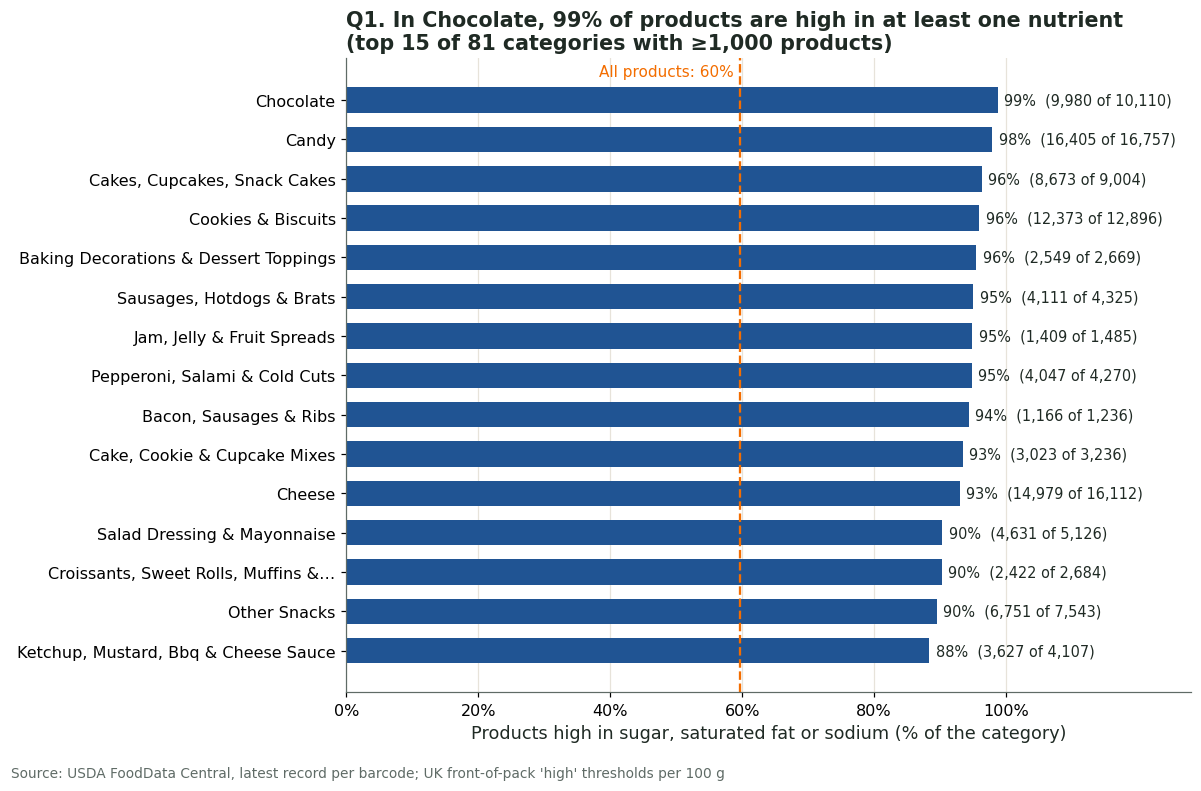

Highest shares: Chocolate 99%; Candy 98%; Cakes, Cupcakes, Snack Cakes 96%
Most high products: Popcorn, Peanuts, Seeds & Related Snacks 17,518; Candy 16,405; Cheese 14,979


In [ ]:
q1 = big_cats.sort_values("share_high", ascending=False).head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7.2))
bars = ax.barh([short(c) for c in q1.index], q1["share_high"] * 100, color=USDA_BLUE, height=0.65)
for bar, (_, r) in zip(bars, q1.iterrows()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{r.share_high:.0%}  ({int(r.high_products):,} of {int(r.products):,})", va="center", fontsize=9.5)
ax.axvline(overall_high * 100, color=CARROT, linestyle="--", linewidth=1.5)
ax.text(overall_high * 100 - 1, len(q1) - 0.4, f"All products: {overall_high:.0%}", color=CARROT, fontsize=10, ha="right")
ax.set_xlim(0, 128); ax.set_xticks(range(0, 101, 20)); pct_axis(ax); ax.grid(axis="y", visible=False)
ax.set_xlabel("Products high in sugar, saturated fat or sodium (% of the category)")
ax.set_title(f"Q1. In {short(q1.index[-1], 30)}, {q1['share_high'].iloc[-1]:.0%} of products are high in at least one nutrient\n"
             f"(top {TOP_N} of {len(big_cats)} categories with ≥{MIN_PRODUCTS:,} products)")
finish(fig, "USDA FoodData Central, latest record per barcode; UK front-of-pack 'high' thresholds per 100 g")
top3 = big_cats.sort_values("share_high", ascending=False).head(3)
most = big_cats.sort_values("high_products", ascending=False).head(3)
print("Highest shares:", "; ".join(f"{short(c, 50)} {r.share_high:.0%}" for c, r in top3.iterrows()))
print("Most high products:", "; ".join(f"{short(c, 50)} {int(r.high_products):,}" for c, r in most.iterrows()))

**Key takeaways**
- 60% of packaged products are high in at least one nutrient, but the problem is concentrated: chocolate (99%), candy (98%) and cakes (96%) lead, and every category in the top 15 is at 88% or more.
- By number of products, the largest groups of high products are popcorn, nuts and seeds (17,518), candy (16,405) and cheese (14,979).

**Implication:** reviews should start with a small set of shelves, led by candy and cheese, which combine a high share with a large number of products.

#### Q2. Nutrient Drivers by Category
**Business question.** For the categories identified in Q1, which nutrient (sugar, saturated fat or salt) makes their products "high"? This determines what a reviewer should check on each shelf.

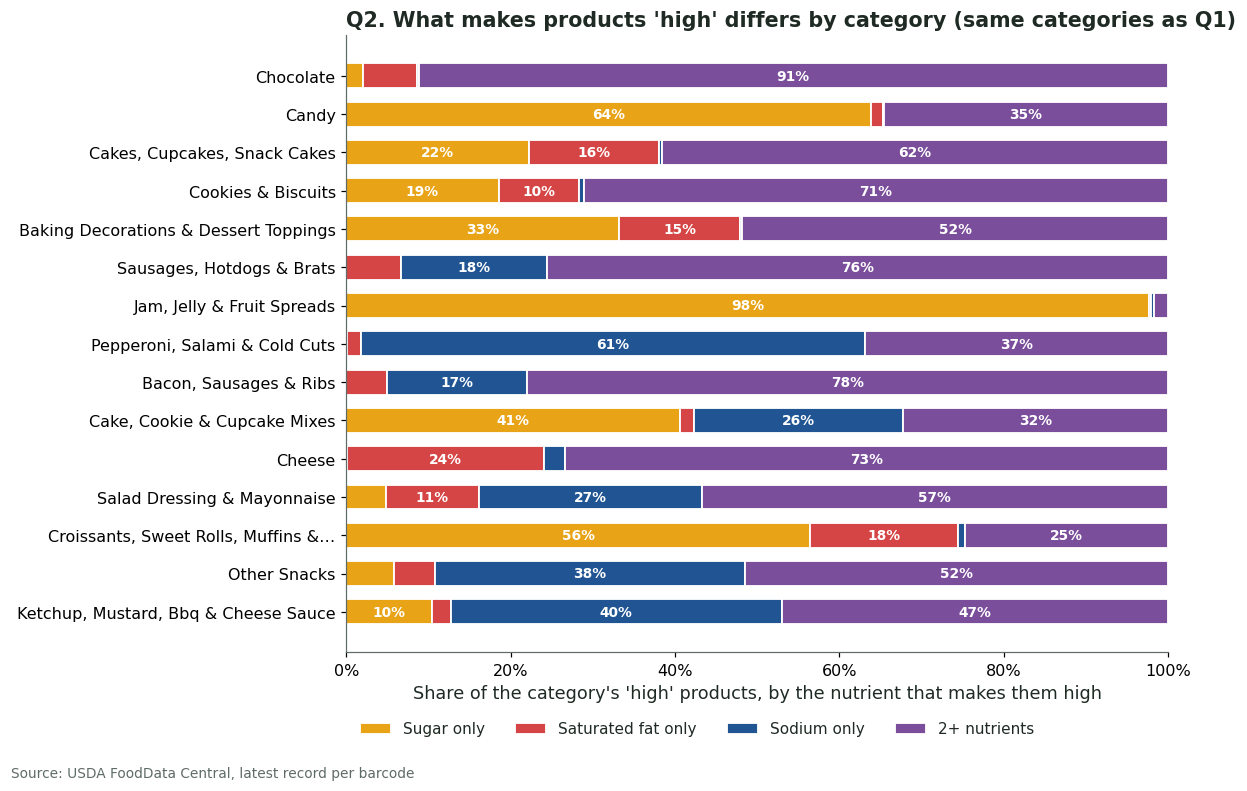

Main reason by category: {'2+ nutrients': 10, 'Sugar only': 4, 'Sodium only': 1}
All high products: Sugar only 21%, Saturated fat only 18%, Sodium only 20%, 2+ nutrients 42%


In [ ]:
DRIVERS = ["Sugar only", "Saturated fat only", "Sodium only", "2+ nutrients"]
DRIVER_COLORS = [NUTRIENT_COLORS["Sugar"], NUTRIENT_COLORS["Saturated fat"], NUTRIENT_COLORS["Sodium"], NUTRIENT_COLORS["2+ nutrients"]]
high_p = p1[p1["any_high"]].copy()
high_p["driver"] = np.select([high_p["high_count"] >= 2, high_p["high_sugar"], high_p["high_sat_fat"], high_p["high_sodium"]],
                             ["2+ nutrients", "Sugar only", "Saturated fat only", "Sodium only"], default="2+ nutrients")
q2 = (pd.crosstab(high_p["branded_food_category"], high_p["driver"], normalize="index")
        .reindex(columns=DRIVERS, fill_value=0).reindex(q1.index))
fig, ax = plt.subplots(figsize=(11, 7.2))
left = np.zeros(len(q2))
for d, col in zip(DRIVERS, DRIVER_COLORS):
    vals = q2[d].values * 100
    ax.barh([short(c) for c in q2.index], vals, left=left, color=col, height=0.65, edgecolor="white", linewidth=1.2, label=d)
    for i, v in enumerate(vals):
        if v >= 8:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    left += vals
ax.set_xlim(0, 100); pct_axis(ax); ax.grid(False)
ax.set_xlabel("Share of the category's 'high' products, by the nutrient that makes them high")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.09), frameon=False)
main_driver = q2.idxmax(axis=1)
ax.set_title("Q2. What makes products 'high' differs by category (same categories as Q1)")
finish(fig, "USDA FoodData Central, latest record per barcode")
overall_mix = high_p["driver"].value_counts(normalize=True).reindex(DRIVERS)
print("Main reason by category:", main_driver.value_counts().to_dict())
print("All high products:", ", ".join(f"{d} {overall_mix[d]:.0%}" for d in DRIVERS))

**Key takeaways**
- Sugar alone drives jams and jellies (98% of their high products) and candy (64%).
- Salt alone drives pepperoni, salami and cold cuts (61%).
- Chocolate (91%), bacon and sausages (78%) and cheese (73%) are high in two or more nutrients at once.

**Implication:** a single store-wide rule is not enough; each shelf needs its own nutrient checklist.

#### Q3. Sodium Variation Within Categories
**Business question.** In which categories does sodium differ most between similar products? Wide variation means lower-sodium alternatives already exist on the same shelf.

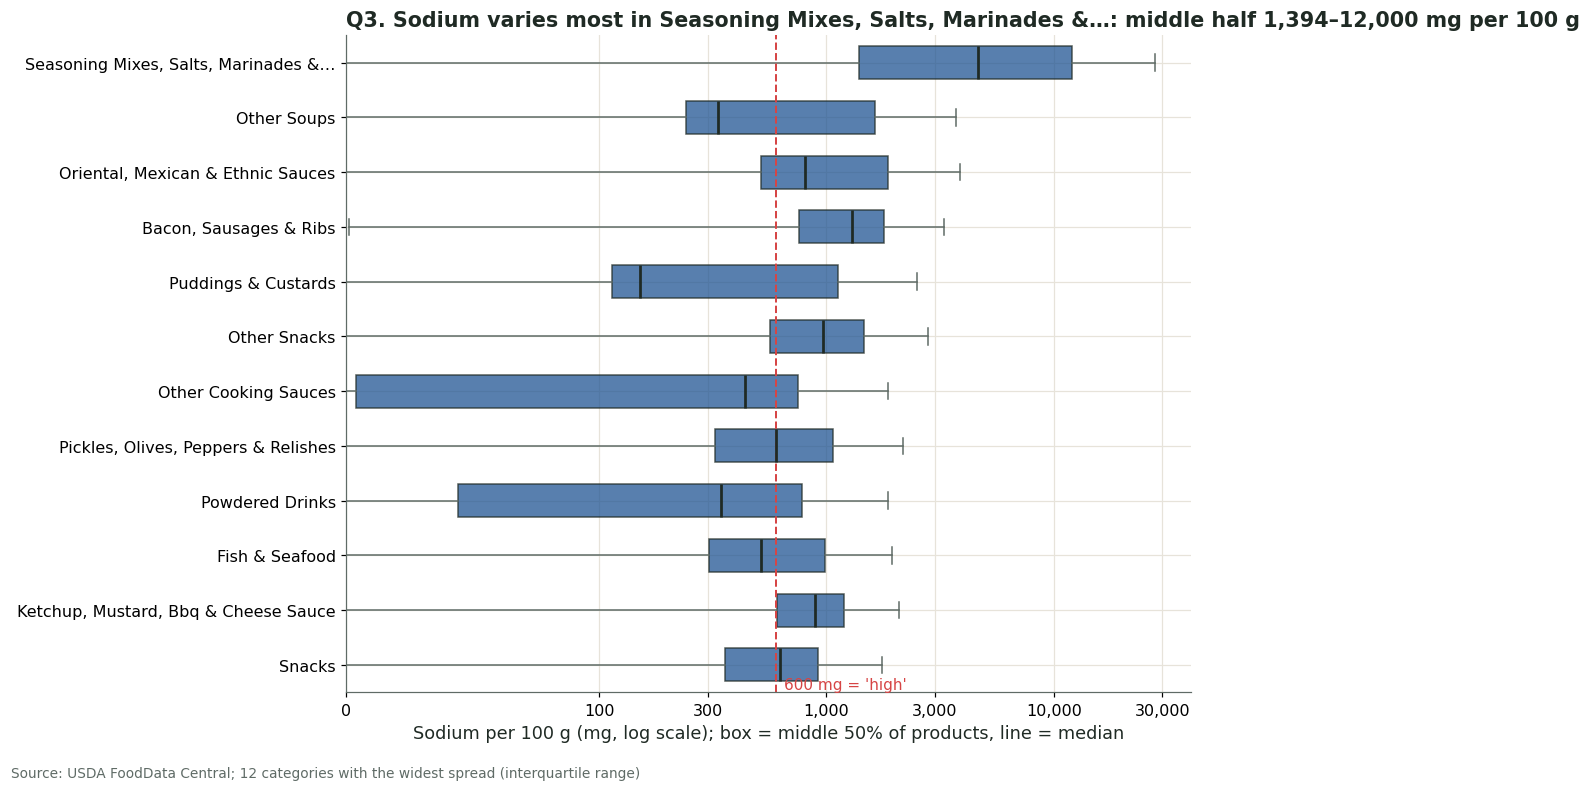

,count,10%,25%,50%,75%,90%,IQR
branded_food_category,,,,,,,
"seasoning mixes, salts, marinades & tenderizers",3647.0,333.0,1394.0,4625.0,12000.0,25500.0,10606.0
other soups,2815.0,155.0,241.0,335.0,1640.0,4062.0,1400.0
"oriental, mexican & ethnic sauces",2384.0,307.0,514.0,806.0,1867.0,3333.0,1353.0
"bacon, sausages & ribs",1236.0,600.0,757.0,1294.0,1786.0,2071.0,1029.0
puddings & custards,1086.0,64.0,114.0,152.0,1125.0,1582.0,1011.0


In [ ]:
sod_base = p1[p1["branded_food_category"].isin(big_cats.index)]
sod_stats = sod_base.groupby("branded_food_category")["sodium_mg"].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
sod_stats["IQR"] = sod_stats["75%"] - sod_stats["25%"]
q3 = sod_stats.sort_values("IQR", ascending=False).head(12)
order3 = q3.index[::-1]
fig, ax = plt.subplots(figsize=(11, 7.2))
box_data = [sod_base.loc[sod_base["branded_food_category"].eq(c), "sodium_mg"].dropna().values for c in order3]
box_style = dict(showfliers=False, patch_artist=True, widths=0.6, medianprops=dict(color=INK, linewidth=1.8),
                 whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
try:
    bp = ax.boxplot(box_data, orientation="horizontal", **box_style)   # matplotlib 3.10+
except TypeError:
    bp = ax.boxplot(box_data, vert=False, **box_style)                 # older matplotlib (e.g. Colab)
for patch in bp["boxes"]:
    patch.set_facecolor(NUTRIENT_COLORS["Sodium"]); patch.set_alpha(0.75); patch.set_edgecolor(INK)
ax.set_yticks(range(1, len(order3) + 1), [short(c) for c in order3])
ax.set_xscale("symlog", linthresh=100)
ax.set_xticks([0, 100, 300, 1000, 3000, 10000, 30000])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(0, 40000)
ax.axvline(600, color=TOMATO, linestyle="--", linewidth=1.3)
ax.text(650, 0.55, "600 mg = 'high'", color=TOMATO, fontsize=10)
ax.set_xlabel("Sodium per 100 g (mg, log scale); box = middle 50% of products, line = median")
ax.set_title(f"Q3. Sodium varies most in {short(q3.index[0], 40)}: middle half {q3['25%'].iloc[0]:,.0f}–{q3['75%'].iloc[0]:,.0f} mg per 100 g")
finish(fig, "USDA FoodData Central; 12 categories with the widest spread (interquartile range)")
display(q3[["count", "10%", "25%", "50%", "75%", "90%", "IQR"]].head(5).round(0))

**Key takeaways**
- Seasoning mixes and marinades vary the most: the middle half of products ranges from 1,394 to 12,000 mg of sodium per 100 g.
- Soups (241–1,640 mg) and Asian, Mexican and other ethnic sauces (514–1,867 mg) follow; part of the spread reflects dry versus ready-to-eat forms.

**Implication:** in sauces and soups, the store can steer shoppers to lower-sodium versions it already stocks, comparing like-for-like product forms.

In [ ]:
def tidy(s):
    return s.astype("string").str.replace(r"[\[\]]", "", regex=True).str.strip().str.lower().replace("", pd.NA)

p2 = latest.copy()
p2["owner"] = tidy(p2["brand_owner"])
p2["category"] = tidy(p2["branded_food_category"])
p2 = p2.dropna(subset=["owner", "category"])
p2 = p2[~p2["owner"].isin(["unknown", "not available", "n/a"])].copy()
print(f"Products with an identified owner and category: {len(p2):,}; brand owners: {p2['owner'].nunique():,}")

Products with an identified owner and category: 435,283; brand owners: 22,596


### 4.2 The brands behind the products (USDA)

#### Q4. Brand Performance vs. Category Benchmark
**Business question.** Which brand owners have more or fewer high products than expected for the categories they sell in? Comparing each company with its own category avoids penalizing, for example, a candy maker simply for making candy. We test whether the share of high products differs by brand owner (chi-square test, owners with 100+ products).

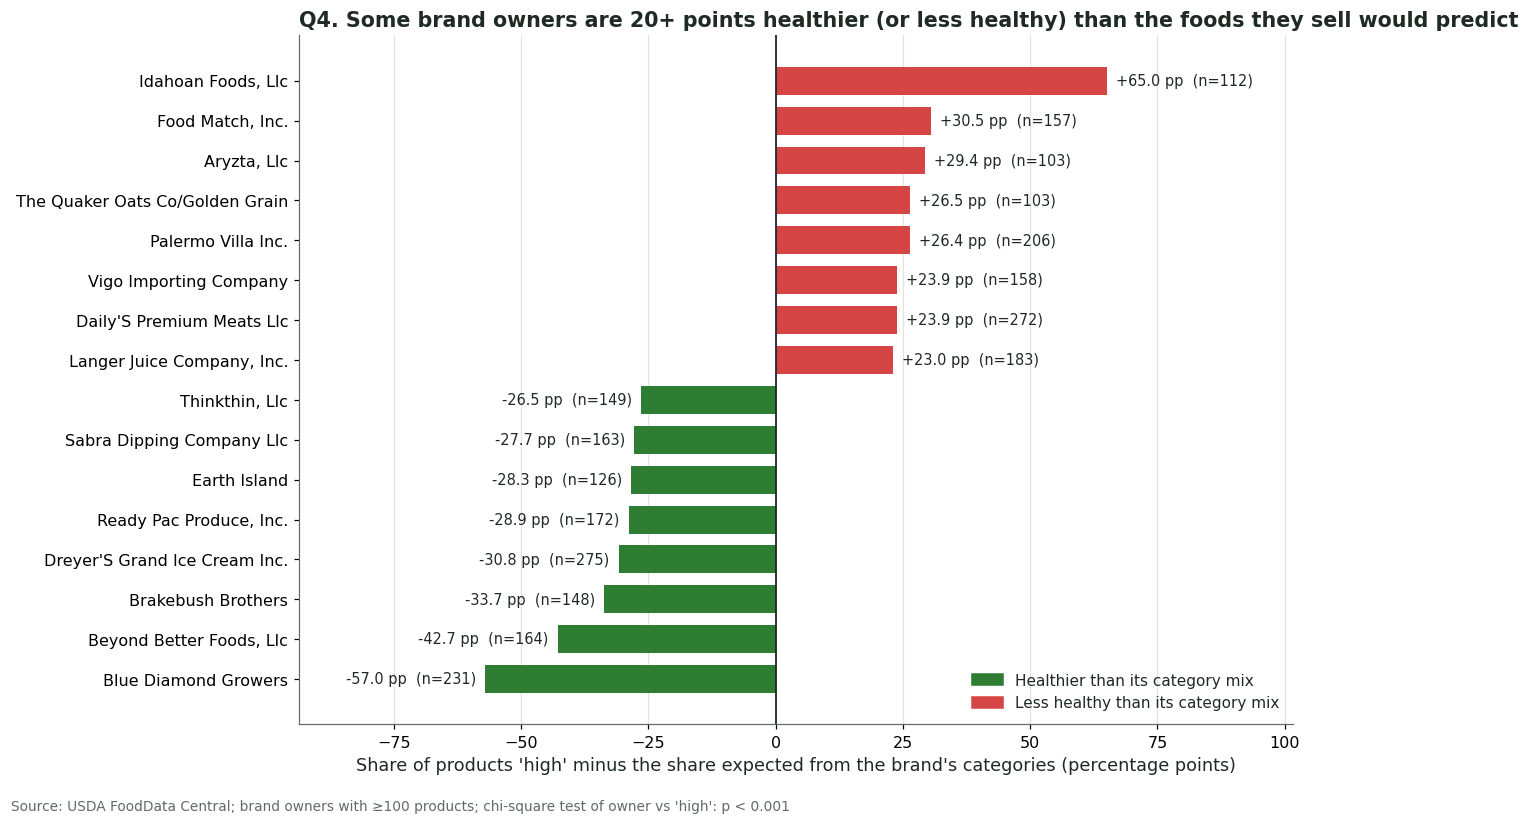

Brand owners compared: 467; chi-square = 42,947 (df = 466), p < 0.001
Healthiest vs expectation: Blue Diamond Growers -57.0, Beyond Better Foods, Llc -42.7, Brakebush Brothers -33.7
Least healthy vs expectation: Idahoan Foods, Llc +65.0, Food Match, Inc. +30.5, Aryzta, Llc +29.4


In [ ]:
q5_base = p2.loc[p2["has_core_nutrients"] & p2["any_high"].notna()].copy()
cat_sizes = q5_base["category"].value_counts()
q5_base = q5_base[q5_base["category"].isin(cat_sizes[cat_sizes >= 100].index)].copy()
q5_base["category_expected"] = q5_base.groupby("category")["any_high"].transform("mean")
q5_summary = q5_base.groupby("owner").agg(n_products=("gtin_key", "nunique"), observed=("any_high", "mean"),
                                          expected=("category_expected", "mean"))
q5_summary = q5_summary[q5_summary["n_products"] >= 100].copy()
q5_summary["gap_pp"] = (q5_summary["observed"] - q5_summary["expected"]) * 100
q5_plot = pd.concat([q5_summary.nsmallest(8, "gap_pp"), q5_summary.nlargest(8, "gap_pp")]).sort_values("gap_pp")

# Test: does the share of 'high' products depend on the brand owner (brands with 100+ products)?
chi2_5, p5, dof5, _ = stats.chi2_contingency(pd.crosstab(q5_base.loc[q5_base["owner"].isin(q5_summary.index), "owner"],
                                                          q5_base.loc[q5_base["owner"].isin(q5_summary.index), "any_high"]))
fig, ax = plt.subplots(figsize=(12, 7.5))
bars = ax.barh([short(o, 40) for o in q5_plot.index], q5_plot["gap_pp"],
               color=[LEAF if g < 0 else TOMATO for g in q5_plot["gap_pp"]], height=0.7)
ax.axvline(0, color=INK, linewidth=1.2)
for bar, g, n in zip(bars, q5_plot["gap_pp"], q5_plot["n_products"]):
    ax.annotate(f"{g:+.1f} pp  (n={n:,})", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6 if g >= 0 else -6, 0), textcoords="offset points", va="center", ha="left" if g >= 0 else "right", fontsize=9.5)
ax.margins(x=0.3); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of products 'high' minus the share expected from the brand's categories (percentage points)")
ax.legend(handles=[Patch(color=LEAF, label="Healthier than its category mix"), Patch(color=TOMATO, label="Less healthy than its category mix")],
          loc="lower right", frameon=False)
ax.set_title("Q4. Some brand owners are 20+ points healthier (or less healthy) than the foods they sell would predict")
finish(fig, f"USDA FoodData Central; brand owners with ≥100 products; chi-square test of owner vs 'high': {fmt_p(p5)}")
print(f"Brand owners compared: {len(q5_summary)}; chi-square = {chi2_5:,.0f} (df = {dof5}), {fmt_p(p5)}")
print("Healthiest vs expectation:", ", ".join(f"{short(o, 40)} {g:+.1f}" for o, g in q5_summary.nsmallest(3, "gap_pp")["gap_pp"].items()))
print("Least healthy vs expectation:", ", ".join(f"{short(o, 40)} {g:+.1f}" for o, g in q5_summary.nlargest(3, "gap_pp")["gap_pp"].items()))

**Key takeaways**
- The share of high products differs significantly by brand owner (467 companies, p < 0.001).
- Blue Diamond Growers (−57 points), Beyond Better Foods (−43) and Brakebush Brothers (−34) perform far better than their category benchmark.
- Idahoan Foods (+65), Food Match (+31) and Aryzta (+29) perform far worse.

**Implication:** supplier reviews should benchmark each company against its category and start with those furthest above it.

#### Q5. Store Brands vs. Name Brands
**Business question.** Are the store's own brands (e.g. Great Value, Good & Gather, Kirkland) healthier than name brands in the same categories? The store controls its own recipes, so this is its most direct lever. We test whether store brands have a lower share of high products (pooled two-proportion z-test).

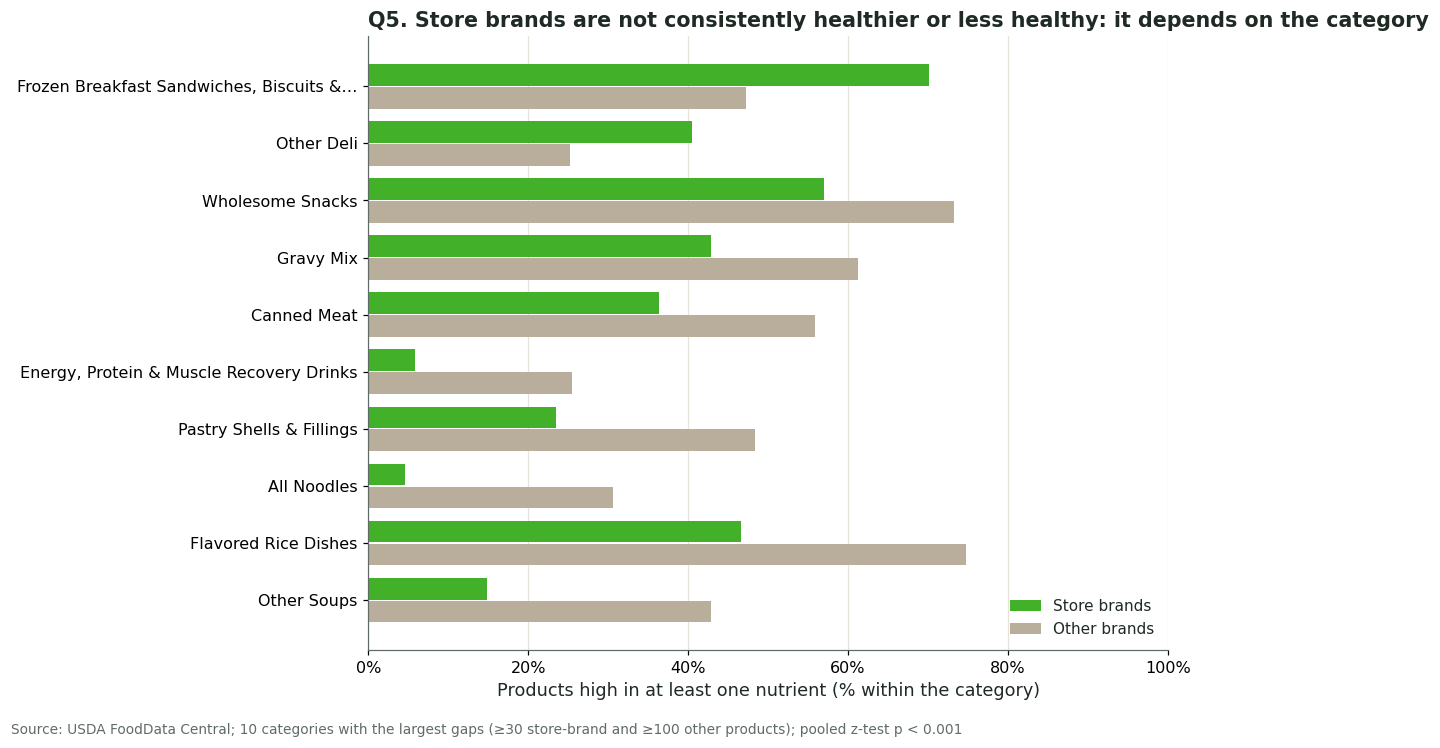

Store-brand products identified: 31,158; eligible categories: 101
Pooled share 'high': store brands 54.2% vs other brands 61.3% (z = -24.5, p < 0.001); store brands higher in 45 of 101 categories


In [ ]:
# Store brands are identified with a reviewable list of US retailer-owned brand names (exact matches only).
PRIVATE_LABEL_NAMES = {"great value", "equate", "marketside", "bettergoods", "good & gather", "market pantry", "favorite day",
    "up & up", "kirkland signature", "365 by whole foods market", "365 everyday value", "simple truth", "private selection",
    "kroger", "signature select", "o organics", "open nature", "trader joe's", "aldi", "simply nature", "specially selected",
    "happy farms", "friendly farms", "millville", "member's mark", "wegmans", "food lion", "hannaford", "stop & shop",
    "publix", "greenwise", "h-e-b", "hill country fare"}
q6 = p2.loc[p2["has_core_nutrients"] & p2["any_high"].notna()].copy()
q6["brand_label"] = tidy(q6["brand_name"])
q6["is_store_brand"] = q6["brand_label"].isin(PRIVATE_LABEL_NAMES) | q6["owner"].isin(PRIVATE_LABEL_NAMES)
grp = q6.groupby(["category", "is_store_brand"]).agg(n=("gtin_key", "nunique"), high=("any_high", "sum"), share=("any_high", "mean")).unstack()
eligible = grp[(grp[("n", True)] >= 30) & (grp[("n", False)] >= 100)].copy()
eligible["diff_pp"] = (eligible[("share", True)] - eligible[("share", False)]) * 100
sel = eligible.reindex(eligible["diff_pp"].abs().sort_values(ascending=False).head(10).index).sort_values("diff_pp")

# Test across all eligible categories: store vs other brands, pooled two-proportion z-test
z6, p6 = proportions_ztest([eligible[("high", True)].sum(), eligible[("high", False)].sum()],
                           [eligible[("n", True)].sum(), eligible[("n", False)].sum()])
store_share = eligible[("high", True)].sum() / eligible[("n", True)].sum()
other_share = eligible[("high", False)].sum() / eligible[("n", False)].sum()

fig, ax = plt.subplots(figsize=(11, 6.8))
y = np.arange(len(sel))
ax.barh(y + 0.2, sel[("share", True)] * 100, height=0.38, color=INSTACART_GREEN, label="Store brands")
ax.barh(y - 0.2, sel[("share", False)] * 100, height=0.38, color=OAT, label="Other brands")
ax.set_yticks(y, [short(c, 40) for c in sel.index]); pct_axis(ax); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("Products high in at least one nutrient (% within the category)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Q5. Store brands are not consistently healthier or less healthy: it depends on the category")
finish(fig, f"USDA FoodData Central; 10 categories with the largest gaps (≥30 store-brand and ≥100 other products); pooled z-test {fmt_p(p6)}")
print(f"Store-brand products identified: {q6['is_store_brand'].sum():,}; eligible categories: {len(eligible)}")
print(f"Pooled share 'high': store brands {store_share:.1%} vs other brands {other_share:.1%} (z = {z6:.1f}, {fmt_p(p6)}); "
      f"store brands higher in {(eligible['diff_pp'] > 0).sum()} of {len(eligible)} categories")

**Key takeaways**
- Across 101 categories, 54.2% of store-brand products are high versus 61.3% of other brands (p < 0.001).
- However, store brands are less healthy than name brands in 45 of those 101 categories, for example frozen breakfast sandwiches and deli items.

**Implication:** the store should review its own brand category by category and reformulate where it trails name brands. (Store brands are identified from a reviewable list of retailer brand names.)

#### Q6. Missing Nutrition Data by Company
**Business question.** Which companies leave out sugar, saturated fat or salt values on their products? Without these values the store cannot assess a product at all.

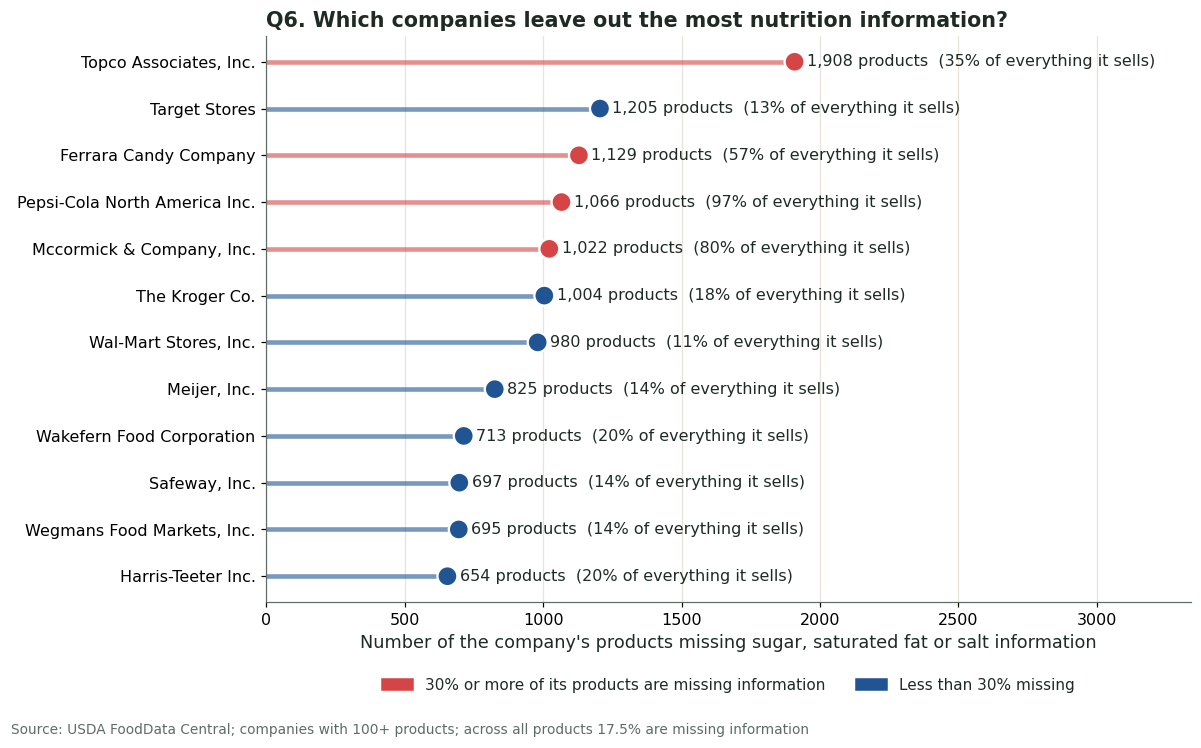

,total,missing,missing_rate
owner,,,
"topco associates, inc.",5435,1908,35.1
target stores,9145,1205,13.2
ferrara candy company,1975,1129,57.2
pepsi-cola north america inc.,1101,1066,96.8
"mccormick & company, inc.",1285,1022,79.5


In [ ]:
q7 = p2.groupby("owner").agg(total=("gtin_key", "nunique"), missing=("missing_core_nutrients", "sum"))
q7 = q7[q7["total"] >= 100].copy()
q7["missing_rate"] = 100 * q7["missing"] / q7["total"]
q7 = q7.sort_values(["missing", "missing_rate"], ascending=False)
q7_plot = q7.head(12).iloc[::-1]                            # biggest at the top

# Lollipop chart: a thin line and a dot per company (easy to read, less heavy than bars)
fig, ax = plt.subplots(figsize=(11, 6.8))
y = np.arange(len(q7_plot))
colors7 = [TOMATO if r >= 30 else USDA_BLUE for r in q7_plot["missing_rate"]]
ax.hlines(y, 0, q7_plot["missing"], color=colors7, linewidth=3, alpha=0.6)
ax.scatter(q7_plot["missing"], y, color=colors7, s=170, zorder=3, edgecolor="white", linewidth=1.5)
for i, (_, r) in enumerate(q7_plot.iterrows()):
    ax.text(r.missing + 45, i, f"{int(r.missing):,} products  ({r.missing_rate:.0f}% of everything it sells)", va="center", fontsize=10.5)
ax.set_yticks(y, [short(o, 34) for o in q7_plot.index]); ax.set_xlim(0, q7_plot["missing"].max() * 1.75); ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of the company's products missing sugar, saturated fat or salt information")
ax.legend(handles=[Patch(color=TOMATO, label="30% or more of its products are missing information"),
                   Patch(color=USDA_BLUE, label="Less than 30% missing")], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2)
ax.set_title(f"Q6. Which companies leave out the most nutrition information?")
finish(fig, f"USDA FoodData Central; companies with 100+ products; across all products {latest['missing_core_nutrients'].mean():.1%} are missing information")
display(q7.head(5).round(1))

**Key takeaways**
- 17.5% of all products are missing at least one of the three values.
- Topco Associates, a store-brand supplier, has the most incomplete products (1,908; 35% of its range), followed by Target (1,205; 13%).
- Pepsi-Cola (97%), McCormick (80%) and Ferrara Candy (57%) are missing values for most of their products.

**Implication:** the store should request complete nutrition data from these suppliers before ranking their products; a missing USDA value is a data gap to verify, not proof of a wrong package label.

**Section summary (4.2):** suppliers differ widely in both nutrition and data quality, and store brands are healthier on average but not in every category.

### 4.3 Reliability of label information (USDA and official standards)

#### Q7. Accuracy of Nutrient Claims
**Business question.** When a product's name claims "low sodium", "sugar free", "high fiber" or "high protein", do its own label values meet the FDA definition of that claim? A store that promotes these claims needs them to be correct. We test whether at least 95% of claim products comply (one-sided binomial test).

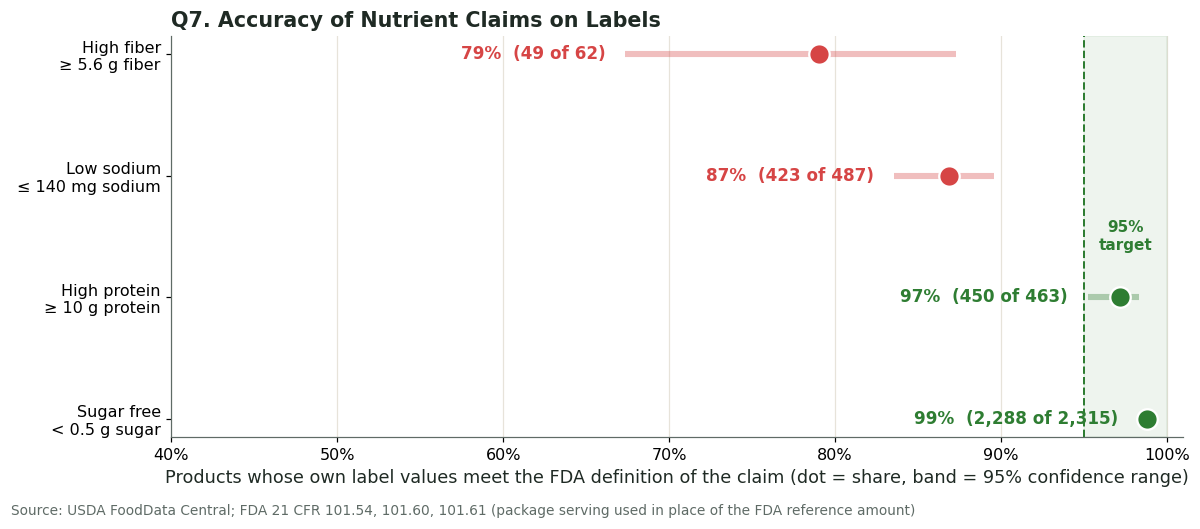

'High fiber' products meeting the pre-2016 rule (>= 5 g): 93.5%


,rule,products,meets,meet_rule,ci_low,ci_high,p_vs_95
claim,,,,,,,
Sugar free,< 0.5 g sugar,2315,2288,98.834,98.308,99.197,1.000
High protein,≥ 10 g protein,463,450,97.192,95.256,98.352,0.993
Low sodium,≤ 140 mg sodium,487,423,86.858,83.567,89.573,0.000
High fiber,≥ 5.6 g fiber,62,49,79.032,67.361,87.316,0.000


In [ ]:
CLAIMS = {  # claim: (regex on the product name, per-serving column, FDA rule, label)
    "Low sodium":   (r"\blow[\s-]sodium\b", "sodium_mg_serving", lambda v: v <= 140, "≤ 140 mg sodium"),
    "Sugar free":   (r"\bsugar[\s-]?free\b|\bzero sugar\b", "total_sugars_g_serving", lambda v: v < 0.5, "< 0.5 g sugar"),
    "High fiber":   (r"\bhigh[\s-]fiber\b", "fiber_g_serving", lambda v: v >= 5.6, "≥ 5.6 g fiber"),
    "High protein": (r"\bhigh[\s-]protein\b", "protein_g_serving", lambda v: v >= 10, "≥ 10 g protein"),
}
rows = []
for claim, (pattern, col, rule, label) in CLAIMS.items():
    claimed = latest[latest["description"].str.contains(pattern, case=False, regex=True) & latest[col].notna()]
    meets = rule(claimed[col])
    test = stats.binomtest(int(meets.sum()), len(claimed), p=0.95, alternative="less")
    lo, hi = proportion_confint(int(meets.sum()), len(claimed), method="wilson")
    rows.append({"claim": claim, "rule": label, "products": len(claimed), "meets": int(meets.sum()), "meet_rule": meets.mean() * 100,
                 "ci_low": lo * 100, "ci_high": hi * 100, "p_vs_95": test.pvalue})
claims = pd.DataFrame(rows).set_index("claim").sort_values("meet_rule", ascending=False)
old_fiber = latest[latest["description"].str.contains(CLAIMS["High fiber"][0], case=False) & latest["fiber_g_serving"].notna()]

# Dot chart with 95% confidence ranges against the 95% target
fig, ax = plt.subplots(figsize=(11, 4.8))
y = np.arange(len(claims))
ax.axvspan(95, 100, color=LEAF, alpha=0.08)
ax.axvline(95, color=LEAF, linestyle="--", linewidth=1.3)
for i, (c, r) in enumerate(claims.iterrows()):
    col = LEAF if r.meet_rule >= 95 else TOMATO
    ax.hlines(i, r.ci_low, r.ci_high, color=col, linewidth=4, alpha=0.35)
    ax.scatter(r.meet_rule, i, s=180, color=col, zorder=3, edgecolor="white", linewidth=1.5)
    ax.text(r.ci_low - 1.2, i, f"{r.meet_rule:.0f}%  ({r.meets:,} of {r.products:,})", ha="right", va="center", fontsize=11, fontweight="bold", color=col)
ax.set_yticks(y, [f"{c}\n{r}" for c, r in zip(claims.index, claims["rule"])])
ax.set_xlim(40, 101); pct_axis(ax); ax.grid(axis="y", visible=False)
ax.text(97.5, 1.5, "95%\ntarget", ha="center", va="center", fontsize=10, color=LEAF, fontweight="bold")
ax.set_xlabel("Products whose own label values meet the FDA definition of the claim (dot = share, band = 95% confidence range)")
ax.set_title("Q7. Accuracy of Nutrient Claims on Labels")
finish(fig, "USDA FoodData Central; FDA 21 CFR 101.54, 101.60, 101.61 (package serving used in place of the FDA reference amount)")
print(f"'High fiber' products meeting the pre-2016 rule (>= 5 g): {(old_fiber['fiber_g_serving'] >= 5).mean():.1%}")
display(claims.round(3))

**Key takeaways**
- "Sugar free" (99% of 2,315 products) and "high protein" (97% of 463) meet the 95% standard.
- "Low sodium" falls short: only 87% of 487 products have 140 mg or less per serving (p < 0.001), so roughly 1 in 8 claims is not supported by the label values.
- "High fiber" shows 79% compliance, but 93.5% of these products meet the pre-2016 fiber rule, which points to outdated labels rather than false claims.

**Implication:** "low sodium" products should be verified before they are featured in promotions or shelf tags. (The FDA applies claims per reference amount; we used the package serving size.)

#### Q8. UK vs. FDA Sodium Standards
**Business question.** Do the UK standard (more than 600 mg per 100 g) and the FDA standard (460 mg or more per serving) identify the same products as high in sodium? The store must choose one standard for its shelf tags. We test whether the two standards disagree (McNemar test on paired classifications).

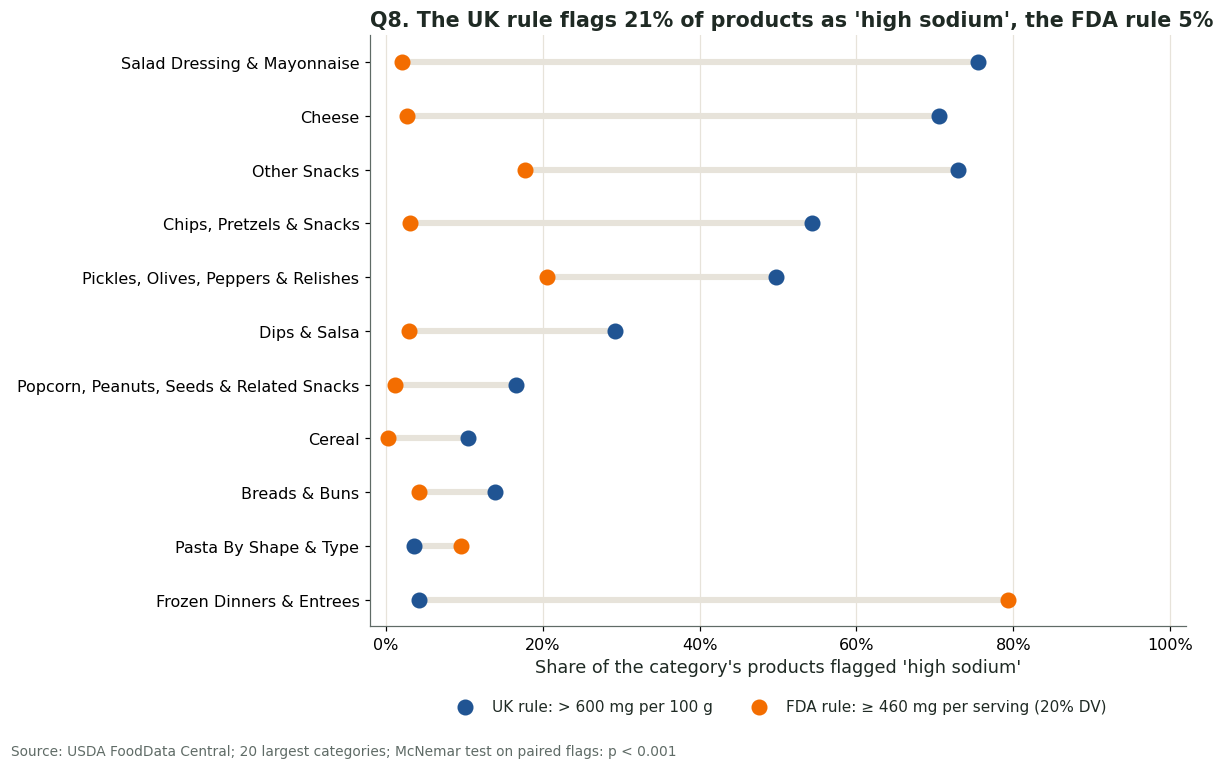

fda_high_sodium,False,True
high_sodium,,
False,141021,5953
True,35174,3515


McNemar chi-square = 20,760, p < 0.001


In [ ]:
top20 = latest.loc[latest["has_core_nutrients"], "branded_food_category"].value_counts().head(20).index
h11 = latest[latest["has_core_nutrients"] & latest["fda_high_sodium"].notna() & latest["branded_food_category"].isin(top20)].copy()
h11["fda_high_sodium"] = h11["fda_high_sodium"].astype(bool)
tab11 = pd.crosstab(h11["high_sodium"], h11["fda_high_sodium"])
res11 = mcnemar(tab11.values, exact=False, correction=True)
by_cat = h11.groupby("branded_food_category")[["high_sodium", "fda_high_sodium"]].mean() * 100
by_cat = by_cat[(by_cat > 5).any(axis=1)]
by_cat = by_cat.assign(gap=by_cat["high_sodium"] - by_cat["fda_high_sodium"]).sort_values("gap")

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(by_cat))
ax.hlines(y, by_cat["fda_high_sodium"], by_cat["high_sodium"], color=GRID, linewidth=4)
ax.scatter(by_cat["high_sodium"], y, color=NUTRIENT_COLORS["Sodium"], s=90, zorder=3, label="UK rule: > 600 mg per 100 g")
ax.scatter(by_cat["fda_high_sodium"], y, color=CARROT, s=90, zorder=3, label="FDA rule: ≥ 460 mg per serving (20% DV)")
ax.set_yticks(y, [short(c, 40) for c in by_cat.index]); pct_axis(ax); ax.set_xlim(-2, 102); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the category's products flagged 'high sodium'")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_title(f"Q8. The UK rule flags {h11['high_sodium'].mean():.0%} of products as 'high sodium', the FDA rule {h11['fda_high_sodium'].mean():.0%}")
finish(fig, f"USDA FoodData Central; 20 largest categories; McNemar test on paired flags: {fmt_p(res11.pvalue)}")
display(tab11)
print(f"McNemar chi-square = {res11.statistic:,.0f}, {fmt_p(res11.pvalue)}")

**Key takeaways**
- The two standards disagree substantially (p < 0.001): the UK rule flags 21% of products and the FDA rule only 5%.
- Salad dressings, cheese and chips are high per 100 g but are eaten in small servings, so only the UK rule flags them.
- Frozen dinners show the opposite: 4% are high per 100 g, but 79% per serving, because one serving is a full meal.

**Implication:** the standard should be chosen deliberately: per 100 g for comparing products within an aisle, per serving for consumer-facing labels.

**Section summary (4.3):** most label claims are reliable, "low sodium" needs verification, and the choice of standard changes which products appear high in sodium.

### 4.4 Purchasing behavior (USDA × Instacart)
This part uses the combined dataset: 8.07 million packaged-food purchases with nutrition data, of which 41.2% are high in at least one nutrient.

#### Q9. Unhealthy Purchase Volume by Aisle
**Business question.** In which aisles do shoppers buy the largest number of products that are high in sugar, saturated fat or salt? We rank aisles by volume and report the match coverage so that poorly matched aisles are not over-interpreted.

Matched packaged-food purchases: 8,068,293; share flagged 'high': 41.2%


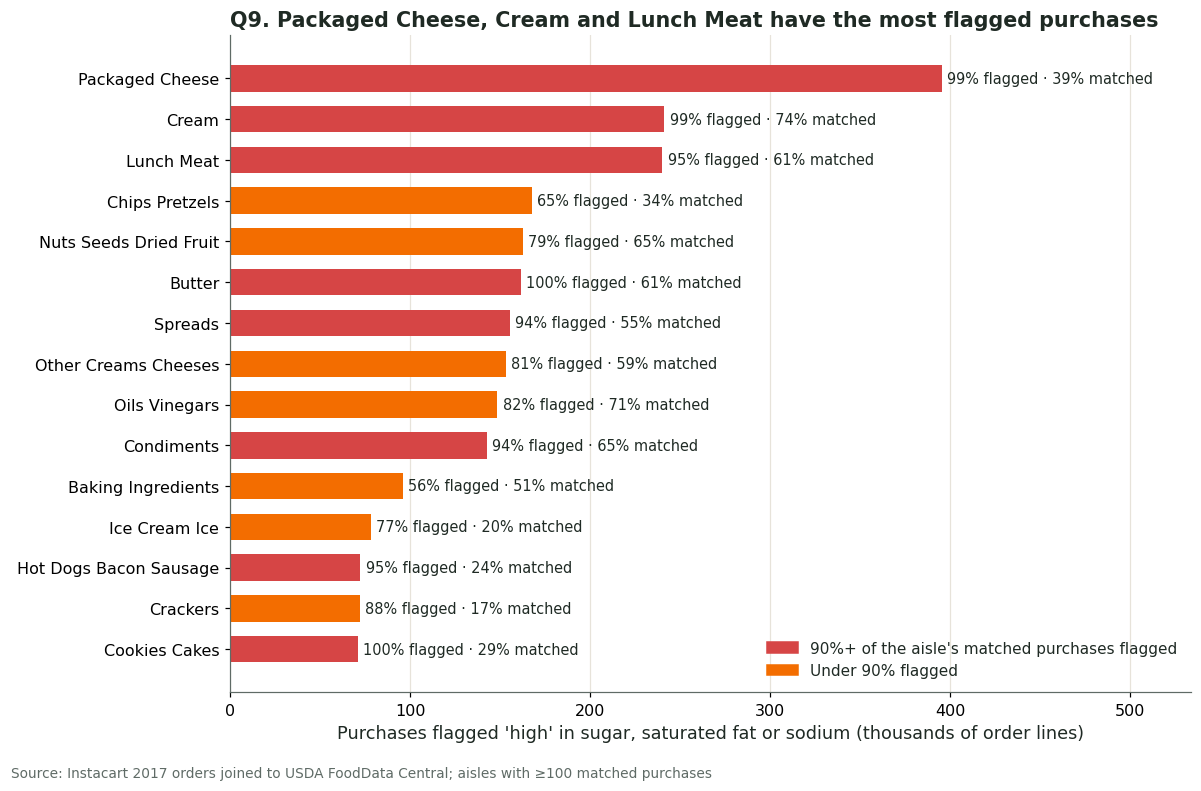

,total_purchases,high_share,match_coverage
aisle,,,
breakfast bars pastries,1222,100.00,1.63
butter,161588,99.93,61.00
cookies cakes,71209,99.65,29.18
trail mix snack mix,23605,99.41,63.71
packaged cheese,398427,99.21,39.01


,total_purchases,flagged_purchases,high_share,match_coverage
aisle,,,,
packaged cheese,398427,395298,99.21,39.01
cream,244408,241202,98.69,73.98
lunch meat,252027,240146,95.29,61.16
chips pretzels,257004,167710,65.26,34.10
nuts seeds dried fruit,206058,162559,78.89,64.59


In [ ]:
# Packaged-food purchase lines with USDA nutrition and a valid 'high' flag
matched = basket[basket["is_packaged_food"] & basket["usda_matched"] & basket["any_high"].notna()].copy()
matched["any_high"] = matched["any_high"].astype(bool)
aisle_summary = matched.groupby("aisle", observed=True).agg(total_purchases=("any_high", "size"), high_purchases=("any_high", "sum"))
aisle_summary["high_share"] = aisle_summary["high_purchases"] / aisle_summary["total_purchases"] * 100
aisle_summary["all_purchases"] = basket[basket["is_packaged_food"]].groupby("aisle", observed=True)["product_id"].size()
aisle_summary["match_coverage"] = aisle_summary["total_purchases"] / aisle_summary["all_purchases"] * 100
aisle_summary = aisle_summary[aisle_summary["total_purchases"] >= 100].copy()
aisle_summary.index = aisle_summary.index.astype(str)
aisle_summary["flagged_purchases"] = aisle_summary["high_purchases"]
print(f"Matched packaged-food purchases: {len(matched):,}; share flagged 'high': {matched['any_high'].mean():.1%}")

top_volume = aisle_summary.sort_values("flagged_purchases", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7.2))
bars = ax.barh(top_volume.index.str.title(), top_volume["flagged_purchases"] / 1000,
               color=[TOMATO if s >= 90 else CARROT for s in top_volume["high_share"]], height=0.65)
for bar, (_, r) in zip(bars, top_volume.iterrows()):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2,
            f"{r.high_share:.0f}% flagged · {r.match_coverage:.0f}% matched", va="center", fontsize=9.5)
ax.margins(x=0.35); ax.grid(axis="y", visible=False)
ax.set_xlabel("Purchases flagged 'high' in sugar, saturated fat or sodium (thousands of order lines)")
ax.legend(handles=[Patch(color=TOMATO, label="90%+ of the aisle's matched purchases flagged"), Patch(color=CARROT, label="Under 90% flagged")],
          frameon=False, loc="lower right")
ax.set_title(f"Q9. {top_volume.index[-1].title()}, {top_volume.index[-2].title()} and {top_volume.index[-3].title()} have the most flagged purchases")
finish(fig, "Instacart 2017 orders joined to USDA FoodData Central; aisles with ≥100 matched purchases")
display(aisle_summary.sort_values("high_share", ascending=False).head(5)[["total_purchases", "high_share", "match_coverage"]].round(2))
display(aisle_summary.sort_values("flagged_purchases", ascending=False).head(5)[["total_purchases", "flagged_purchases", "high_share", "match_coverage"]].round(2))

**Key takeaways**
- Ranked by share alone, small aisles appear worst (breakfast bars and pastries are 100% high), but only 1.6% of that aisle could be matched.
- Ranked by volume, three aisles dominate: packaged cheese (395,298 high purchases; 99% of the aisle), cream (241,202; 99%) and lunch meat (240,146; 95%), all with 39–74% match coverage.

**Implication:** priorities should be set by volume and data coverage together; packaged cheese, cream and lunch meat are the first candidates.

#### Q10. Unhealthy Share of Shopping Baskets
**Business question.** How much of a typical shopping basket is unhealthy, and do most baskets contain a mix of healthy and unhealthy items? A mixed basket means a healthier swap is relevant to almost every shopper. We test whether the average basket is less than half unhealthy (one-sided t-test, baskets with 5+ matched items).

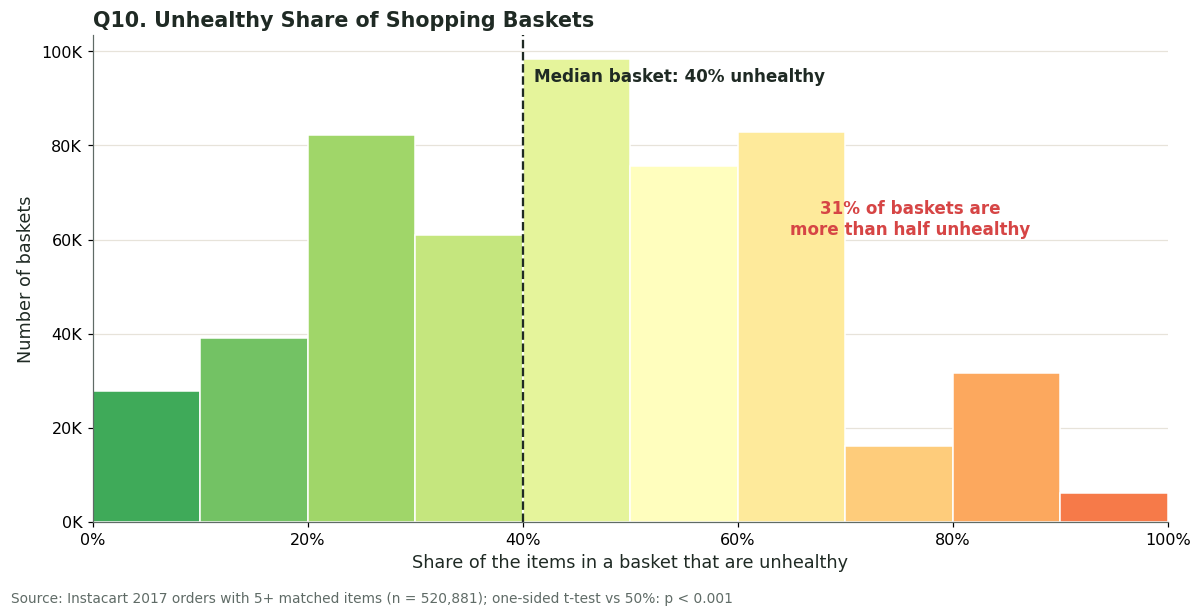

Baskets: 520,881; median 40.0% unhealthy; mean 42.4%; more than half unhealthy: 31.3%; mixed (some healthy, some unhealthy): 93.6%; all healthy: 5.2%


In [ ]:
# Share of each basket (order) that is unhealthy, for orders with at least 5 matched items
basket_share = matched.groupby("order_id")["any_high"].agg(items="size", share="mean")
basket_share = basket_share[basket_share["items"] >= 5].copy()
basket_share["share"] *= 100
med = basket_share["share"].median()
over_half = (basket_share["share"] > 50).mean() * 100
mixed = basket_share["share"].between(1, 99).mean() * 100
t10 = stats.ttest_1samp(basket_share["share"], 50, alternative="less")

fig, ax = plt.subplots(figsize=(11, 5.6))
bins = [-0.01, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100.01]          # 10-point groups
counts, edges, patches = ax.hist(basket_share["share"], bins=bins, edgecolor="white", linewidth=1)
for p, left in zip(patches, edges[:-1]):                       # green (healthier) to red (unhealthier)
    p.set_facecolor(plt.cm.RdYlGn_r(0.15 + 0.7 * left / 100))
ax.axvline(med, color=INK, linestyle="--", linewidth=1.5)
ax.text(med + 1, counts.max() * 0.95, f"Median basket: {med:.0f}% unhealthy", fontsize=11, fontweight="bold")
ax.text(76, counts.max() * 0.62, f"{over_half:.0f}% of baskets are\nmore than half unhealthy", fontsize=11, color=TOMATO, fontweight="bold", ha="center")
pct_axis(ax, "x"); ax.set_xlim(0, 100); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}K"))
ax.set_xlabel("Share of the items in a basket that are unhealthy")
ax.set_ylabel("Number of baskets")
ax.set_title("Q10. Unhealthy Share of Shopping Baskets")
finish(fig, f"Instacart 2017 orders with 5+ matched items (n = {len(basket_share):,}); one-sided t-test vs 50%: {fmt_p(t10.pvalue)}")
print(f"Baskets: {len(basket_share):,}; median {med:.1f}% unhealthy; mean {basket_share['share'].mean():.1f}%; "
      f"more than half unhealthy: {over_half:.1f}%; mixed (some healthy, some unhealthy): {mixed:.1f}%; all healthy: {(basket_share['share'] == 0).mean() * 100:.1f}%")

**Key takeaways**
- Across 520,881 baskets, the median basket is 40% unhealthy and the average 42% (significantly below 50%, p < 0.001).
- 94% of baskets mix healthy and unhealthy items; only 5% contain no unhealthy items at all.
- 31% of baskets are more than half unhealthy.

**Implication:** nearly every shopper buys at least some unhealthy products, so swap suggestions reach almost every basket rather than a small group of customers.

#### Q11. Repeat Purchase of Healthier Products
**Business question.** Are healthier products bought again as often as unhealthy ones? If the store promotes healthier products, it needs to know whether shoppers keep buying them. We test whether the repeat-purchase rate is higher for healthier products, overall (two-proportion z-test) and within aisles (Wilcoxon signed-rank test).

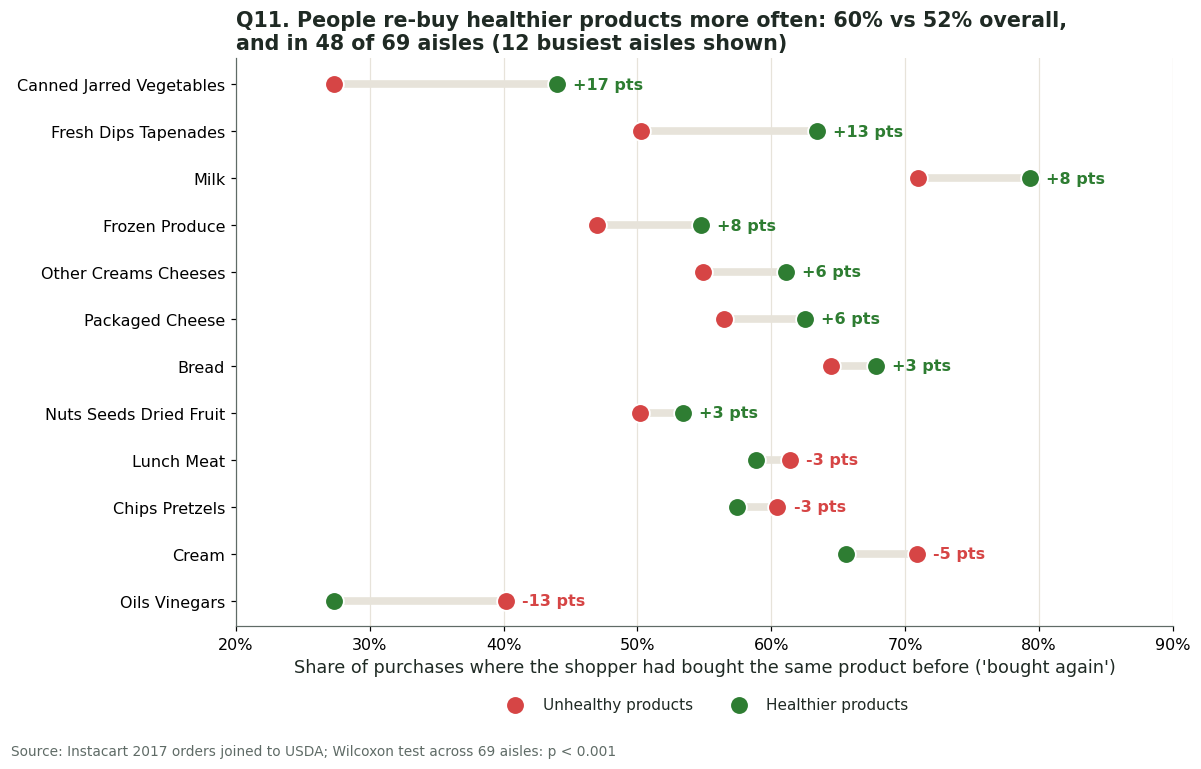

Overall: unflagged 59.6% vs flagged 52.4% (z = 203.7, p < 0.001). Within aisles: unflagged reordered more in 48 of 69 aisles, median gap +3.9 points, Wilcoxon p < 0.001


In [ ]:
q15 = matched.groupby("any_high")["reordered"].agg(purchase_lines="size", reorder_rate="mean")
q15["reorder_rate"] *= 100
q15 = q15.reindex([False, True])          # row order: not flagged, flagged
z15, p15 = proportions_ztest(matched.groupby("any_high")["reordered"].sum().reindex([False, True]).values,
                             q15["purchase_lines"].values, alternative="larger")
# Within the same aisle (compares similar products): one point per aisle
aisle_rr = matched.pivot_table(index="aisle", columns="any_high", values="reordered", aggfunc=["mean", "size"], observed=True)
aisle_rr = aisle_rr[(aisle_rr["size"] >= 1000).all(axis=1)]
rr = pd.DataFrame({"flagged": aisle_rr["mean"][True] * 100, "not_flagged": aisle_rr["mean"][False] * 100,
                   "purchases": aisle_rr["size"].sum(axis=1)})
rr_gap = rr["not_flagged"] - rr["flagged"]
w15 = stats.wilcoxon(rr_gap, alternative="greater")

# Dot comparison: for the 12 busiest aisles, how often people re-buy healthier (green) vs unhealthy (red) products
top_rr = rr.sort_values("purchases", ascending=False).head(12).assign(gap=lambda d: d["not_flagged"] - d["flagged"]).sort_values("gap")
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(top_rr))
ax.hlines(y, top_rr["flagged"], top_rr["not_flagged"], color=GRID, linewidth=5)
ax.scatter(top_rr["flagged"], y, color=TOMATO, s=150, zorder=3, label="Unhealthy products", edgecolor="white", linewidth=1.2)
ax.scatter(top_rr["not_flagged"], y, color=LEAF, s=150, zorder=3, label="Healthier products", edgecolor="white", linewidth=1.2)
for i, (_, r) in enumerate(top_rr.iterrows()):
    ax.text(max(r.flagged, r.not_flagged) + 1.2, i, f"{r.gap:+.0f} pts", va="center", fontsize=10.5, fontweight="bold",
            color=LEAF if r.gap > 0 else TOMATO)
ax.set_yticks(y, top_rr.index.str.title()); pct_axis(ax); ax.set_xlim(20, 90); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of purchases where the shopper had bought the same product before ('bought again')")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_title(f"Q11. People re-buy healthier products more often: {q15.loc[False, 'reorder_rate']:.0f}% vs {q15.loc[True, 'reorder_rate']:.0f}% overall,\n"
             f"and in {(rr_gap > 0).sum()} of {len(rr)} aisles (12 busiest aisles shown)")
finish(fig, f"Instacart 2017 orders joined to USDA; Wilcoxon test across {len(rr)} aisles: {fmt_p(w15.pvalue)}")
print(f"Overall: unflagged {q15.loc[False, 'reorder_rate']:.1f}% vs flagged {q15.loc[True, 'reorder_rate']:.1f}% (z = {z15:.1f}, {fmt_p(p15)}). "
      f"Within aisles: unflagged reordered more in {(rr_gap > 0).sum()} of {len(rr)} aisles, median gap {rr_gap.median():+.1f} points, Wilcoxon {fmt_p(w15.pvalue)}")

**Key takeaways**
- Healthier products are bought again 59.6% of the time versus 52.4% for unhealthy products, a 7.2-point gap (p < 0.001).
- The pattern holds within aisles: healthier products have the higher repeat rate in 48 of 69 aisles (median gap +3.9 points).
- Among the 12 busiest aisles, the largest gaps are in canned vegetables (+17 points), dips (+13) and milk (+8); lunch meat, chips, cream and oils go the other way.

**Implication:** promoting healthier products is unlikely to reduce customer loyalty. The result shows an association, not causation, so the store should pilot changes and monitor repeat purchases.

#### Q12. Top Products to Review
**Business question.** Which individual products account for the most unhealthy purchases, and which limit does each one exceed? This turns the aisle-level priorities into a concrete product review list.

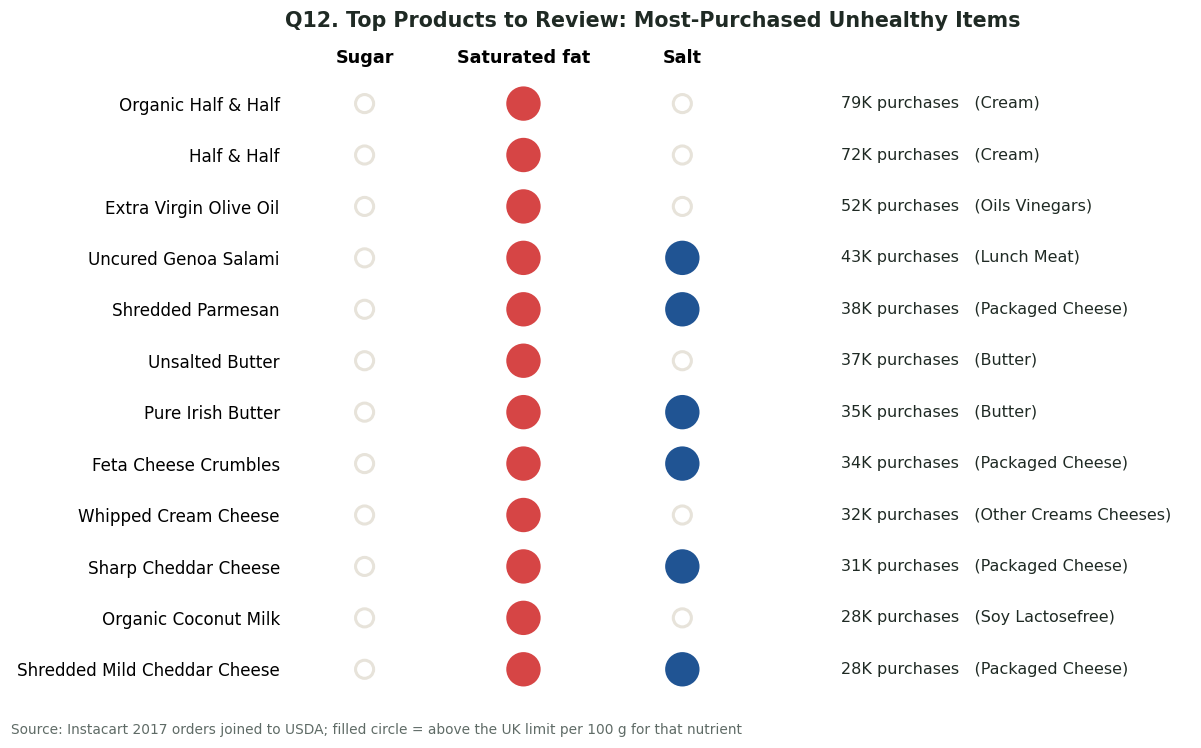

These 12 products account for 510,021 unhealthy purchases (15.3% of all matched unhealthy purchases)
                product_name                aisle  purchases high_sugar high_sat_fat high_sodium
         Organic Half & Half                cream      79006      False         True       False
                 Half & Half                cream      71641      False         True       False
      Extra Virgin Olive Oil        oils vinegars      52323      False         True       False
        Uncured Genoa Salami           lunch meat      43261      False         True        True
           Shredded Parmesan      packaged cheese      37689      False         True        True
             Unsalted Butter               butter      37102      False         True       False
           Pure Irish Butter               butter      35384      False         True        True
        Feta Cheese Crumbles      packaged cheese      33800      False         True        True
        Whipped Cream Chee

In [ ]:
# The 12 most-bought unhealthy products and which limit(s) each one breaks
top_products = (ic_products[ic_products["usda_matched"] & ic_products["any_high"].fillna(False).astype(bool)]
                .nlargest(12, "purchases").iloc[::-1])
nut_cols = [("high_sugar", "Sugar", NUTRIENT_COLORS["Sugar"]), ("high_sat_fat", "Saturated fat", NUTRIENT_COLORS["Saturated fat"]),
            ("high_sodium", "Salt", NUTRIENT_COLORS["Sodium"])]
fig, ax = plt.subplots(figsize=(11, 6.8))
for j, (col, lab, colr) in enumerate(nut_cols):
    flags = top_products[col].fillna(False).astype(bool).values
    ax.scatter(np.full(len(top_products), j), np.arange(len(top_products)), s=[420 if f else 140 for f in flags],
               c=[colr if f else "white" for f in flags], edgecolors=[colr if f else GRID for f in flags], linewidths=2, zorder=3)
for i, (_, r) in enumerate(top_products.iterrows()):
    ax.text(3.0, i, f"{r.purchases / 1000:,.0f}K purchases   ({short(r.aisle, 22)})", va="center", fontsize=10.5)
ax.set_xticks(range(3), [lab for _, lab, _ in nut_cols], fontsize=11.5, fontweight="bold"); ax.xaxis.tick_top()
ax.set_yticks(range(len(top_products)), [short(n, 34) for n in top_products["product_name"]], fontsize=11)
ax.set_xlim(-0.5, 5.2); ax.set_ylim(-0.6, len(top_products) - 0.4); ax.grid(False)
for side in ["left", "bottom"]: ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.set_title("Q12. Top Products to Review: Most-Purchased Unhealthy Items", pad=30)
finish(fig, "Instacart 2017 orders joined to USDA; filled circle = above the UK limit per 100 g for that nutrient")
share_top = top_products["purchases"].sum() / matched["any_high"].sum() * 100
print(f"These 12 products account for {top_products['purchases'].sum():,} unhealthy purchases ({share_top:.1f}% of all matched unhealthy purchases)")
print(top_products[["product_name", "aisle", "purchases", "high_sugar", "high_sat_fat", "high_sodium"]].iloc[::-1].to_string(index=False))

**Key takeaways**
- The 12 most-purchased unhealthy products account for 510,021 purchases, 15% of all matched unhealthy purchases.
- All 12 exceed the saturated-fat limit: half & half, butter, cheeses, salami, cream cheese and coconut milk.
- Half of them (salami, butter and the cheeses) also exceed the salt limit; none of them is high in sugar.

**Implication:** among the store's best sellers, saturated fat and salt, not sugar, are the nutrients to address. Olive oil appears because the UK per-100 g rule counts its saturated fat; it should be reviewed with nutrition expertise rather than treated as a swap target.

#### Q13. Shopper Segments Behind Unhealthy Purchases
**Business question.** Which shoppers account for most unhealthy purchases: occasional or regular customers? This determines who healthier-swap suggestions should target. We compare each segment's share of shoppers with its share of unhealthy items bought (chi-square test across segments).

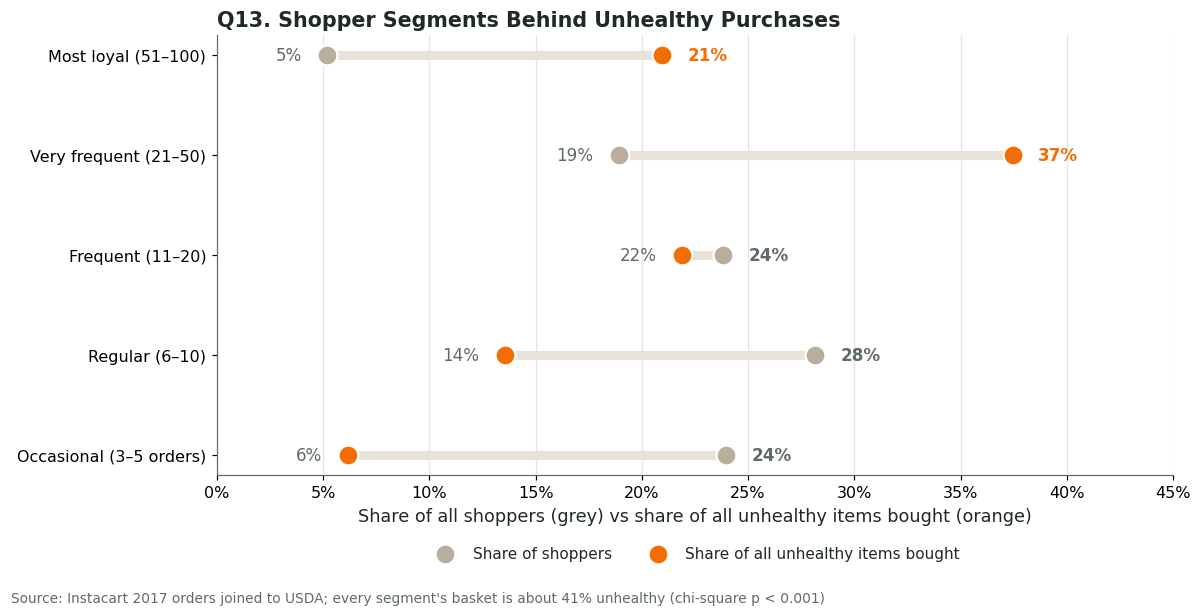

,shoppers,unhealthy_purchases,unhealthy_share
Occasional (3–5 orders),24.0,6.2,41.4
Regular (6–10),28.1,13.5,41.4
Frequent (11–20),23.8,21.9,41.4
Very frequent (21–50),18.9,37.5,41.3
Most loyal (51–100),5.2,20.9,40.9


Frequent shoppers (21+ orders): 24% of shoppers, 58% of unhealthy purchases


In [ ]:
# Shopper segments by how many orders they placed in the data
orders_per_user = orders_clean.groupby("user_id")["order_number"].max()
seg_labels = ["Occasional (3–5 orders)", "Regular (6–10)", "Frequent (11–20)", "Very frequent (21–50)", "Most loyal (51–100)"]
user_seg = pd.cut(orders_per_user, [0, 5, 10, 20, 50, 100], labels=seg_labels)
matched["segment"] = user_seg.reindex(matched["user_id"]).values
seg = pd.DataFrame({
    "shoppers": user_seg.value_counts().reindex(seg_labels) / len(user_seg) * 100,
    "unhealthy_purchases": matched[matched["any_high"]].groupby("segment", observed=True).size().reindex(seg_labels)
                            / matched["any_high"].sum() * 100,
    "unhealthy_share": matched.groupby("segment", observed=True)["any_high"].mean().reindex(seg_labels) * 100})
chi13, p13, _, _ = stats.chi2_contingency(pd.crosstab(matched["segment"], matched["any_high"]))

# Dot comparison: each segment's share of shoppers (grey) vs its share of all unhealthy items bought (orange)
fig, ax = plt.subplots(figsize=(11, 5.6))
y = np.arange(len(seg))
ax.hlines(y, seg["shoppers"], seg["unhealthy_purchases"], color=GRID, linewidth=6)
ax.scatter(seg["shoppers"], y, s=170, color=OAT, zorder=3, edgecolor="white", linewidth=1.5, label="Share of shoppers")
ax.scatter(seg["unhealthy_purchases"], y, s=170, color=CARROT, zorder=3, edgecolor="white", linewidth=1.5, label="Share of all unhealthy items bought")
for i, (_, r) in enumerate(seg.iterrows()):
    left, right = (r.shoppers, r.unhealthy_purchases) if r.shoppers <= r.unhealthy_purchases else (r.unhealthy_purchases, r.shoppers)
    ax.text(left - 1.2, i, f"{left:.0f}%", ha="right", va="center", fontsize=11, color=MUTED)
    ax.text(right + 1.2, i, f"{right:.0f}%", ha="left", va="center", fontsize=11, fontweight="bold", color=CARROT if right == r.unhealthy_purchases else MUTED)
ax.set_yticks(y, seg.index); pct_axis(ax); ax.set_xlim(0, 45); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of all shoppers (grey) vs share of all unhealthy items bought (orange)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax.set_title("Q13. Shopper Segments Behind Unhealthy Purchases")
finish(fig, f"Instacart 2017 orders joined to USDA; every segment's basket is about 41% unhealthy (chi-square {fmt_p(p13)})")
display(seg.round(1))
top2 = seg.iloc[-2:]
print(f"Frequent shoppers (21+ orders): {top2['shoppers'].sum():.0f}% of shoppers, {top2['unhealthy_purchases'].sum():.0f}% of unhealthy purchases")

**Key takeaways**
- Shoppers with 21 or more orders are 24% of all shoppers but buy 58% of all unhealthy items.
- Occasional shoppers (3–5 orders) are 24% of shoppers but buy only 6% of unhealthy items.
- Every segment's basket is about 41% unhealthy: frequent shoppers do not eat worse, they simply buy more.

**Implication:** targeting healthier suggestions at the store's most frequent shoppers (for example through the app or loyalty program) reaches most unhealthy purchases with a quarter of the customer base.

### 4.5 Recommendation and impact (USDA × Instacart)

#### Q14. Priority Aisles and Recommended Actions
**Business question.** Bringing the previous findings together: in which aisles should the store act first, and what action fits each aisle? The table lists the 10 aisles with the most unhealthy purchases, their unhealthy share, and the number of healthier products shoppers already buy there (500+ purchases each).

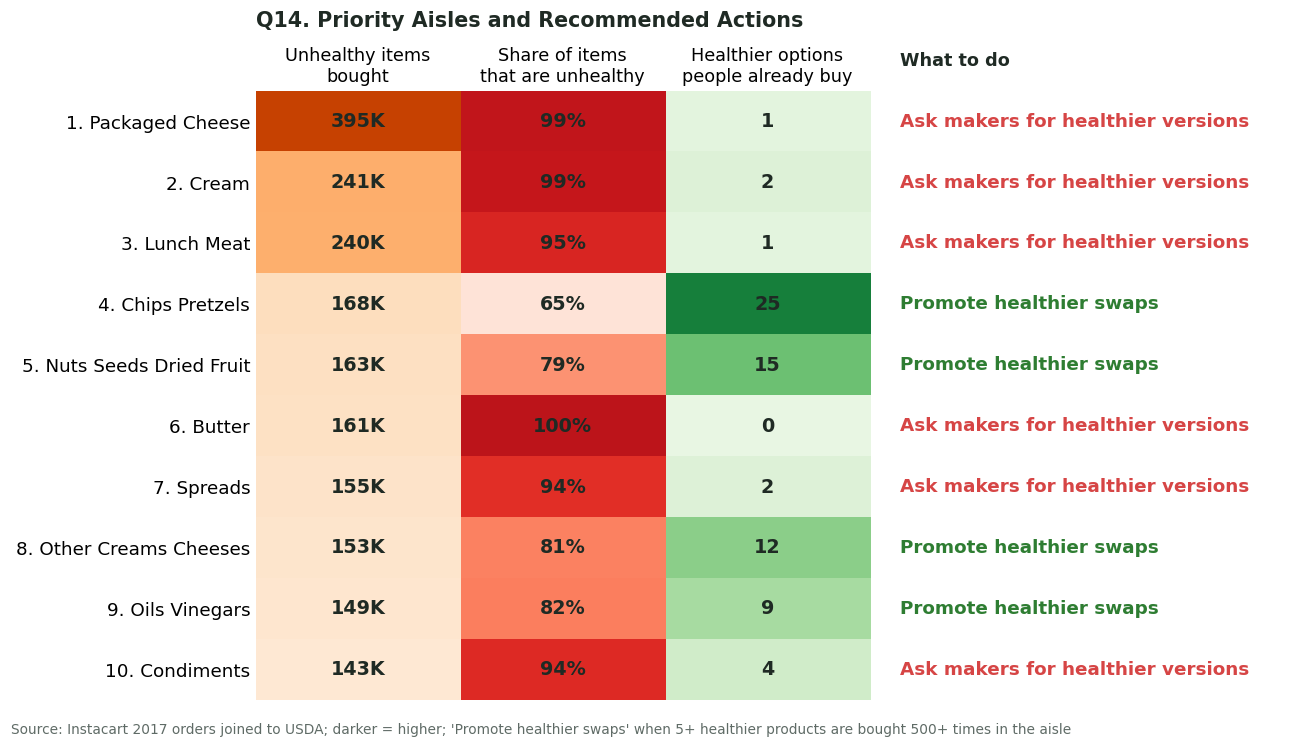

,flagged_purchases,high_share,alternatives,action
aisle,,,,
packaged cheese,395298,99.2,1.0,Ask makers for healthier versions
cream,241202,98.7,2.0,Ask makers for healthier versions
lunch meat,240146,95.3,1.0,Ask makers for healthier versions
chips pretzels,167710,65.3,25.0,Promote healthier swaps
nuts seeds dried fruit,162559,78.9,15.0,Promote healthier swaps
butter,161475,99.9,0.0,Ask makers for healthier versions
spreads,155375,93.8,2.0,Ask makers for healthier versions
other creams cheeses,153269,81.5,12.0,Promote healthier swaps
oils vinegars,148542,81.9,9.0,Promote healthier swaps


In [ ]:
# The answer: popular aisles, often flagged, where well-bought unflagged alternatives already exist
alts = (ic_products[ic_products["usda_matched"] & ic_products["any_high"].notna()]
        .assign(any_high=lambda d: d["any_high"].astype(bool)))
alt_count = alts[~alts["any_high"] & (alts["purchases"] >= 500)].groupby("aisle").size()
q20 = aisle_summary.join(alt_count.rename("alternatives")).fillna({"alternatives": 0})
q20 = q20[q20["total_purchases"] >= 20000].copy()
q20["priority"] = q20["flagged_purchases"] * (q20["alternatives"] > 0)
top20_aisles = q20.sort_values("priority", ascending=False).head(6)

# Color-coded table: the 10 aisles with the most unhealthy items bought, and what to do in each
tbl = q20.sort_values("flagged_purchases", ascending=False).head(10).copy()
tbl["action"] = np.where(tbl["alternatives"] >= 5, "Promote healthier swaps", "Ask makers for healthier versions")
cols = [("flagged_purchases", "Unhealthy items\nbought", lambda v: f"{v / 1000:,.0f}K"),
        ("high_share", "Share of items\nthat are unhealthy", lambda v: f"{v:.0f}%"),
        ("alternatives", "Healthier options\npeople already buy", lambda v: f"{int(v)}")]
vals = np.column_stack([(tbl[c] - tbl[c].min()) / (tbl[c].max() - tbl[c].min() + 1e-9) for c, _, _ in cols])
fig, ax = plt.subplots(figsize=(12, 6.8))
cmaps = ["Oranges", "Reds", "Greens"]
for j in range(len(cols)):
    ax.imshow(np.ma.masked_array(np.zeros_like(vals) + vals, mask=np.ones_like(vals, bool) ^ (np.arange(len(cols)) == j)[None, :].repeat(len(tbl), 0)),
              cmap=cmaps[j], vmin=-0.15, vmax=1.3, aspect="auto", extent=(-0.5, len(cols) - 0.5, len(tbl) - 0.5, -0.5))
for i in range(len(tbl)):
    for j, (c, _, f) in enumerate(cols):
        ax.text(j, i, f(tbl[c].iloc[i]), ha="center", va="center", fontsize=12.5, fontweight="bold", color=INK)
    act = tbl["action"].iloc[i]
    ax.text(len(cols) - 0.35, i, act, ha="left", va="center", fontsize=12, fontweight="bold",
            color=LEAF if act.startswith("Promote") else TOMATO)
ax.set_xticks(range(len(cols)), [lab for _, lab, _ in cols], fontsize=11.5); ax.xaxis.tick_top()
ax.set_yticks(range(len(tbl)), [f"{i + 1}. {a.title()}" for i, a in enumerate(tbl.index)], fontsize=12)
ax.set_xlim(-0.5, len(cols) + 1.6); ax.grid(False)
for side in ["left", "bottom", "top"]: ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.text(len(cols) - 0.35, -0.85, "What to do", fontsize=11.5, fontweight="bold", va="bottom")
ax.set_title("Q14. Priority Aisles and Recommended Actions", pad=42)
finish(fig, "Instacart 2017 orders joined to USDA; darker = higher; 'Promote healthier swaps' when 5+ healthier products are bought 500+ times in the aisle")
display(tbl[["flagged_purchases", "high_share", "alternatives", "action"]].round(1))

**Key takeaways**
- Four aisles already contain several healthier products that shoppers buy: chips and pretzels (25), nuts and seeds (15), other creams and cheeses (12), and oils and vinegars (9).
- Six aisles have almost no healthier alternatives (0–4): packaged cheese, cream, lunch meat, butter, spreads and condiments.

**Implication:** promote healthier swaps in the first group; in the second group, work with manufacturers on lower-salt and lower-fat versions.

#### Q15. Potential Impact of the Recommendations
**Business question.** How much could the recommended actions reduce the share of unhealthy purchases? We model scenarios in which a share of the unhealthy purchases in the priority aisles is replaced by a healthier product, through swaps (4 swap aisles), manufacturer reformulation (6 supplier aisles), or both. These are illustrative scenarios, not forecasts.

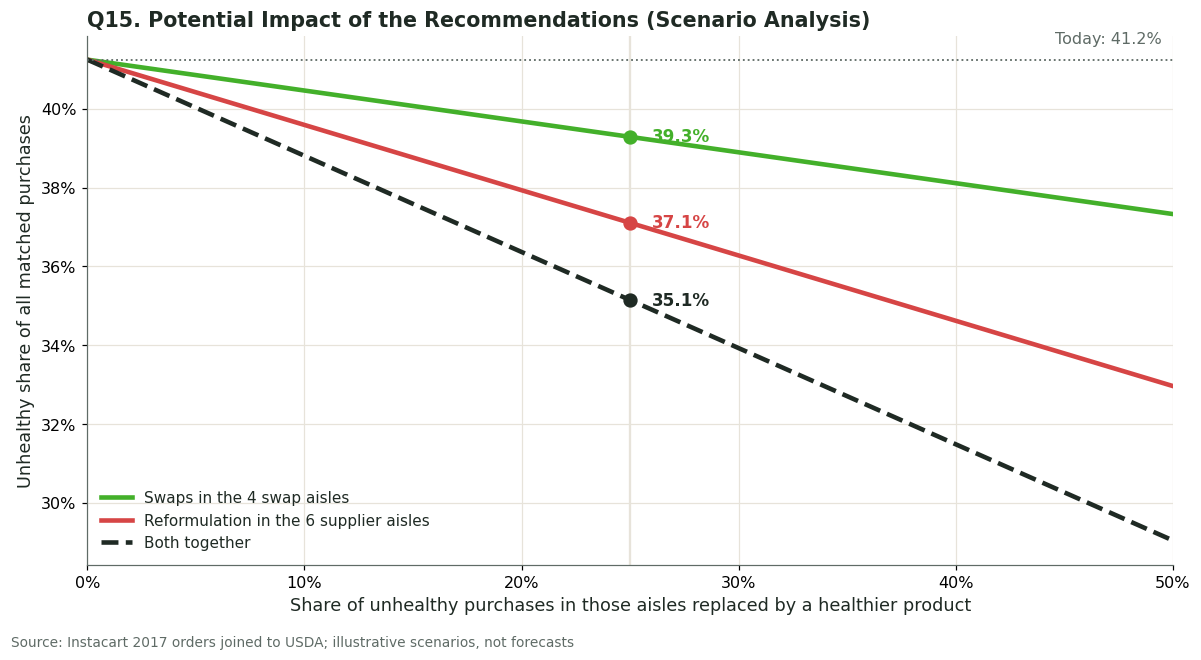

Today: 41.2% of 8,068,293 matched purchases are unhealthy (3,327,606). Swap aisles hold 632,080 unhealthy purchases, supplier aisles 1,336,208.
At 25%: swaps -> 39.3%, reformulation -> 37.1%, both -> 35.1% (492,072 fewer unhealthy purchases)


In [ ]:
# What would the recommendations be worth? Simple scenarios on the matched purchases
swap_aisles = tbl.index[tbl["action"].str.startswith("Promote")]
supplier_aisles = tbl.index[~tbl["action"].str.startswith("Promote")]
N, U = len(matched), matched["any_high"].sum()
in_swap = matched["aisle"].astype(str).isin(swap_aisles)
in_sup = matched["aisle"].astype(str).isin(supplier_aisles)
H_swap, H_sup = (matched["any_high"] & in_swap).sum(), (matched["any_high"] & in_sup).sum()
f = np.linspace(0, 0.5, 51)
scen = pd.DataFrame({"Swaps in the 4 swap aisles": (U - f * H_swap) / N * 100,
                     "Reformulation in the 6 supplier aisles": (U - f * H_sup) / N * 100,
                     "Both together": (U - f * (H_swap + H_sup)) / N * 100}, index=f * 100)

fig, ax = plt.subplots(figsize=(11, 6))
for (name, s), col, ls in zip(scen.items(), [INSTACART_GREEN, TOMATO, INK], ["-", "-", "--"]):
    ax.plot(s.index, s.values, color=col, linewidth=3, linestyle=ls, label=name)
    v = s.loc[25.0]
    ax.scatter([25], [v], color=col, s=70, zorder=3)
    ax.text(26, v, f"{v:.1f}%", va="center", fontsize=11, fontweight="bold", color=col)
ax.axhline(U / N * 100, color=MUTED, linestyle=":", linewidth=1.2)
ax.text(49.5, U / N * 100 + 0.4, f"Today: {U / N * 100:.1f}%", ha="right", fontsize=10.5, color=MUTED)
ax.axvline(25, color=GRID, linewidth=1.5, zorder=0)
pct_axis(ax, "x"); pct_axis(ax, "y"); ax.set_xlim(0, 50)
ax.set_xlabel("Share of unhealthy purchases in those aisles replaced by a healthier product")
ax.set_ylabel("Unhealthy share of all matched purchases")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Q15. Potential Impact of the Recommendations (Scenario Analysis)")
finish(fig, "Instacart 2017 orders joined to USDA; illustrative scenarios, not forecasts")
print(f"Today: {U / N:.1%} of {N:,} matched purchases are unhealthy ({U:,}). Swap aisles hold {H_swap:,} unhealthy purchases, supplier aisles {H_sup:,}.")
print(f"At 25%: swaps -> {scen.loc[25.0].iloc[0]:.1f}%, reformulation -> {scen.loc[25.0].iloc[1]:.1f}%, both -> {scen.loc[25.0].iloc[2]:.1f}% "
      f"({0.25 * (H_swap + H_sup):,.0f} fewer unhealthy purchases)")

**Key takeaways**
- Today 41.2% of the 8.07 million matched purchases are unhealthy; the 10 priority aisles hold 1.97 million of them.
- If 25% of unhealthy purchases in the priority aisles were replaced, the unhealthy share would fall to 39.3% with swaps alone, 37.1% with reformulation alone, and 35.1% with both, about 492,000 fewer unhealthy purchases.
- Reformulation has the larger effect because the supplier aisles hold twice as many unhealthy purchases as the swap aisles.

**Implication:** swaps are the fastest step, but work with manufacturers in the supplier aisles offers the larger gain; together they could lower the unhealthy share by about 6 points.

## 5. Recommendations for the Category Manager

| Priority | Action | Evidence |
|---|---|---|
| 1 | **Promote healthier products shoppers already buy** in chips and pretzels, nuts and seeds, other creams and cheeses, and oils and vinegars | Q11, Q14 |
| 2 | **Work with manufacturers on lower-salt and lower-fat versions** in packaged cheese, cream, lunch meat, butter, spreads and condiments | Q9, Q12, Q14 |
| 3 | **Target healthier suggestions at frequent shoppers** (21+ orders), who buy 58% of unhealthy items | Q13 |
| 4 | **Request complete nutrition data** from the suppliers with the largest gaps (Topco, Target, Pepsi-Cola, McCormick) | Q6 |
| 5 | **Verify "low sodium" claims** before featuring them, and choose one sodium standard for shelf tags | Q7, Q8 |
| 6 | **Review the store's own brand** in the categories where it trails name brands | Q5 |

**Expected impact:** replacing a quarter of unhealthy purchases in the 10 priority aisles would lower the unhealthy share of purchases from 41% to about 35% (Q15). **Success measures:** the unhealthy share of purchases in the priority aisles falls while the repeat-purchase rate holds.

## Conclusion

We set out to help a grocery store's category manager decide where to act first. Joining USDA nutrition data with 33.8 million Instacart purchases made it possible to see, for each matched product, both its nutrition profile and how often it is bought.

**What we learned.** The assortment has a concentrated problem: 60% of packaged products are high in sugar, saturated fat or salt, led by sweets, cheese and processed meats, with a different driving nutrient on each shelf (Q1–Q3). Suppliers differ widely in nutrition and data quality, and one in six products cannot be assessed because values are missing (Q4–Q6). Most label claims are reliable, but "low sodium" needs verification, and the UK and FDA standards disagree on what is high in sodium (Q7–Q8). In the basket, a typical order is 40% unhealthy, unhealthy purchases concentrate in a few aisles and best-selling dairy and meat products, frequent shoppers account for most of them, and shoppers return more often to healthier products (Q9–Q13). The recommended actions split the priority aisles into swap aisles and supplier aisles (Q14), and together could lower the unhealthy share of purchases by about 6 points (Q15).

**Risks and limitations.** The join covers 37% of packaged-food purchases and works best for generic product names. The orders are from 2017 and the labels from 2019–2026. The "high" classification uses UK per-100 g thresholds, which flag some foods such as olive oil, and FDA claims were checked against the package serving. The impact figures are scenarios, and all results are associations rather than causal effects.

**Next steps.** Add brand names to the join to raise coverage in beverages and snacks; add prices to confirm that swaps do not increase basket cost; benchmark products against the FDA's category sodium targets; and pilot swaps in one aisle to measure the real effect on purchases and repeat rates.

## Challenges

- **No shared identifier.** Instacart has no barcode, so we built a standardized product-name key in both datasets. It covers 37% of packaged-food purchases; we report coverage openly.
- **Generic names matched the wrong products.** "Banana" matched banana chips and "Garlic" matched garlic salt, so fresh produce was excluded from the join.
- **Several USDA products per name.** We used their median values; 83% of matched names map to a single category.
- **Repeated USDA records.** 2.0 million records describe 442,097 products; we kept the latest record of each.
- **Data size.** The USDA files are 3.1 GB unzipped; we read them from the zip in chunks and kept only the required columns.
- **Misleading measures.** Ranking aisles by percentage alone favored small, poorly matched aisles (Q9), so we ranked by volume and reported coverage.
- **Choosing useful charts.** Several earlier charts (time of day, cart position, ingredient count, a sodium concentration curve) showed weak effects or did not lead to an action; we replaced them with analyses that support a business decision.
- **Standards and sample size.** UK and FDA standards disagree (Q8), and with millions of rows almost any difference is statistically significant, so we report effect sizes alongside every test.
- **Store-brand identification.** USDA has no store-brand field; Q5 uses a reviewable list of retailer brand names.

## References

1. Professor's Github Notebook: https://github.com/soltaniehha/Intro-to-Data-Analytics/tree/main
2. DataCamp Modules. https://app.datacamp.com/learn/assignments
3. Prof AI Classroom: https://profai.site/student/prof
4. U.S. Food and Drug Administration. *Daily Value on the Nutrition and Supplement Facts Labels* and 21 CFR 101.9 (Daily Values: sodium 2,300 mg, fiber 28 g, protein 50 g). https://www.fda.gov/food/nutrition-facts-label/daily-value-nutrition-and-supplement-facts-labels
5. U.S. Food and Drug Administration. 21 CFR Part 101: 101.54 ("high" = 20% DV or more), 101.60 ("sugar free" < 0.5 g), 101.61 ("low sodium" ≤ 140 mg). https://www.ecfr.gov/current/title-21/chapter-I/subchapter-B/part-101
6. U.S. Food and Drug Administration. *How to Understand and Use the Nutrition Facts Label.* https://www.fda.gov/food/nutrition-facts-label/how-understand-and-use-nutrition-facts-label
7. U.S. Food and Drug Administration. *Use of the Term "Healthy" on Food Labeling* (final rule, 2024) and *Front-of-Package Nutrition Labeling* (proposed rule, 2025). https://www.fda.gov/food/nutrition-food-labeling-and-critical-foods
8. UK Department of Health and Food Standards Agency. *Guide to creating a front of pack (FoP) nutrition label for pre-packed products sold through retail outlets* (2016). https://www.gov.uk/government/publications/front-of-pack-nutrition-labelling-guidance
9. Wickham, H. (2014). Tidy Data. *Journal of Statistical Software*, 59(10).
10. pandas, matplotlib, SciPy, statsmodels and kagglehub documentation. https://pandas.pydata.org · https://matplotlib.org · https://scipy.org · https://www.statsmodels.org · https://github.com/Kaggle/kagglehub
11. Geeks for Geeks Documentation:  https://www.geeksforgeeks.org/

## Generative AI Disclosure

This project was designed, built and validated by Team A09. The team chose the business problem, the datasets, the nutrition standards, the 15 questions and the statistical tests, and interpreted every result. We used generative AI (Claude, Anthropic) as an assistant for the specific tasks below. Every number in this notebook is produced by the code cells from the two datasets; no AI tool produced, filled in or changed any data value.

**How the team used AI**
- **Coding support:** we used Claude to help make our Team Assignment cleaning code more memory-efficient (reading the USDA files from the zip in chunks), to draft code for the Instacart file combination and the `name_key` join, and to debug errors. Team members specified each step and checked the outputs (row counts, match rates, duplicates) before using them.
- **Charts:** team members built Q1–Q6, Q9 and Q11. For Q7, Q8, Q10 and Q12–Q15, and the statistical tests in Q4, Q5 and Q11, the team defined the question and the method and used Claude to draft and debug the plotting code. After a team review found some charts hard to read, we used Claude to restyle all charts to one palette and to redesign Q6, Q10 and Q11 and replace three earlier charts that did not support a decision.
- **Writing:** we used Claude to tighten the wording of the text cells. The findings, takeaways and recommendations come from our analysis, and each statement was checked against the printed outputs.

The OpenAI ingredient-summary demo from the Team Assignment has been removed. Our team reviewed, edited and validated all AI-assisted content to ensure its accuracy, relevance and originality, in line with academic integrity guidelines.